# Flux: evaluation of the NEE of the LI-7500 years (2004-2015)

# About this notebook

The open-path LI-7500 (`IRGA75`) years of this product, 2004-2015, have a weaker net uptake of CO2
than the enclosed-path LI-7200 (`IRGA72`) years from 2016, than the FLUXNET release ONEFlux v1.3 for
CH-Lae, and than Etzold et al. (2011). 2004-2006 come out as a small source. This notebook brings
the evaluation of these years together in one place: the size of the gap, the causes that are ruled
out, the evidence on the size of the open-path correction (opco, Level 1.1 of the documentation),
and where the remaining difference sits. It computes no product.

**What is computed here and what is linked.** The checks that need heavy inputs (20 Hz raw data,
EddyPro settings files) or long sections stay in their own notebooks and are summarised here in one
or two sentences each, with a link:

- [`OPCO_TRANSFER_CHECK_2004-2017`](../30_FLUX_POST-PROCESSING_CHAIN/IRGA75/OPCO_TRANSFER_CHECK_2004-2017.ipynb):
  whether opco, fitted in 2016-2017, holds for the early years
- [`ANALYSER_DAMPING_CHECK_2004-2017`](../30_FLUX_POST-PROCESSING_CHAIN/IRGA75/ANALYSER_DAMPING_CHECK_2004-2017.ipynb):
  EddyPro settings, time lags, signal strength, CO2 gain and the correlation coefficients
- [`RAW_DATA_DIAGNOSTICS_IRGA75_SUMMERS`](../30_FLUX_POST-PROCESSING_CHAIN/IRGA75/RAW_DATA_DIAGNOSTICS_IRGA75_SUMMERS.ipynb):
  covariance, cospectra and noise from the 20 Hz data
- [`FLUX_NEE_IRGA75_COMPARISONS`](FLUX_NEE_IRGA75_COMPARISONS.ipynb): the full comparison with
  FLUXNET and Etzold et al. (2011)
- [`FLUX_NEE_IRGA75_INDEPENDENT_ESTIMATES`](FLUX_NEE_IRGA75_INDEPENDENT_ESTIMATES.ipynb): the
  biometric and soil-respiration estimates of Etzold et al. (2011)
- [`FLUX_NEE_IRGA75_PARTITIONING_COMPARISON`](FLUX_NEE_IRGA75_PARTITIONING_COMPARISON.ipynb):
  `GPP` and `RECO` of the early years against the LI-7200 years

Computed here: the annual sums and the gap; the CO2 gain and zero-offset scenarios; the opco
drivers across the change of 2016, with a refit of opco and its sensitivity to adjusted drivers;
a check of the clocks; the self-heating scale per year from the wind test and the winter test; the
respiration constraint from the LI-7200 years; the correction of Burba et al. (2008) with the
fraction of Järvi et al. (2009) as used by Etzold et al. (2011); the decomposition of the difference
to FLUXNET; the gap-filled winter nights; and a summary of the partitioning.

**Which run is shown.** The notebook reads the outputs of the flux chain as they are on disk, so a
rerun of the chain refreshes every number below. The modification time of each input file is
printed under *Load data*.

**Sign convention and units.** `NEE` is negative when the forest takes up CO2. Half-hourly values
and corrections are in µmol CO2 m⁻² s⁻¹; sums are in gC m⁻² (1 µmol m⁻² s⁻¹ over 30 minutes is
0.0216 gC m⁻²). A correction is stated as the amount it **adds** to the uncorrected flux, so a
positive correction reduces the uptake. opco stores the bias `BIAS_OPCO`; the correction is
`-BIAS_OPCO`.

**Columns used**

- This product, `IRGA75` (`30_FLUX_POST-PROCESSING_CHAIN/IRGA75/05_FPPC_IRGA75_NEE_OPCO_2004-2017`):
  - `NEE_L3.1_L3.3_CUT_50_QCF_gfXG` — `NEE` after all tests, `CUT_50`, gap-filled with XGBoost; the
    main series. `CUT_16` and `CUT_84` for the USTAR range
  - `FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED` — `0` measured, `1` gap-filled
  - `NEE_L3.1_L3.3_CUT_50_QCF` — measured `NEE` after all tests; `NEE_L3.1_L3.2_QCF` before the
    USTAR filter
  - `DAYTIME`, `NIGHTTIME`; `GPP_NT_OF_CUT_50`, `RECO_NT_OF_CUT_50` (nighttime partitioning)
- The input of the chain (`.../IRGA75/01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019`): `FC` (uncorrected),
  `FC_L1.1_OPCO = FC - BIAS_OPCO`, the parts `BIAS_HEAT_OPCO` and `BIAS_WPL_H_OPCO`, and the EddyPro
  and meteo columns named where they are used. The uncorrected input `.../IRGA75/00_...noSHC...` is
  read only for the refit of opco
- The LI-7200, `IRGA72` (`.../IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09` and its input `00`): the same
  series, as the reference without self-heating
- Meteo (`10_METEO/30_PRODUCTS/99_METEO_MERGED_2004-2026.09`): `SW_IN`, `PPFD_IN`, `TA` at 47 m,
  soil temperature at 0.05 m and 0.1 m, soil water at 0.1 m. MeteoSwiss station Lägeren
  (`10_METEO/10_REFERENCE/MeteoSwiss_LAE_30MIN_2004-2026.09`) as an independent reference for wind,
  temperature and radiation
- FLUXNET (`EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1`): `NEE_VUT_REF`, `NEE_VUT_REF_QC`,
  `NIGHT`; the yearly file and the BIF file for the USTAR thresholds

**Day and night.** Comparisons with FLUXNET split by the FLUXNET flag `NIGHT`, as in
[`FLUX_NEE_IRGA75_COMPARISONS`](FLUX_NEE_IRGA75_COMPARISONS.ipynb). Elsewhere the `DAYTIME` and
`NIGHTTIME` flags of this product are used.

# Main findings

The numbers behind each point are in the tables below.

- **The gap.** 2004-2006 average +48 gC m⁻² per year (`CUT_16` to `CUT_84`: +21 to +82), 172
  above the LI-7200 years 2016-2025 (-124). 2007-2009 average -98, 2010-2015 -279. FLUXNET is
  175-240 gC m⁻² per year more negative in every period, Etzold et al. (2011) about 380 more
  negative in 2005-2009. The biometric net ecosystem production of 2006-2009 (307-514) lies
  240-450 above the net uptake of this product (63).
- **No measurement or processing fault.** Analyser damping closes at most 34-54 % of the summer
  daytime gap of 2005-2007; the raw data lose no covariance; the low CO2 reading of 2004-2007
  changes a summer by 11-62 gC m⁻², in either direction; the clocks agree with the MeteoSwiss
  station within about ±15 minutes in every year; adjusting the opco drivers to their level of
  2016-2017 moves 2005-2015 by -32 to +5 gC m⁻² per year on average.
- **Hardware.** One LI-7500 head (75H-0640) served from 2004 to 2017, with no exchange and no
  factory recalibration recorded.
- **Self-heating scale.** The summer wind test gives s = 0.20 ± 0.48 for 2005-2007 and about 1 from
  2008, with the step at the recalibration of December 2007. The winter test of 2004/05-2006/07
  gives 1.41 ± 0.60 against the training months and 1.23 ± 0.30 against the middle winters. If the
  wind test is right, May-September 2005-2007 are 181-203 gC m⁻² per year too positive.
- **Respiration.** The corrected LI-7500 nights lie at 0.79-1.08 of the respiration expected from
  the LI-7200 years; the uncorrected nights below 5 °C at 0.03-0.72. A possible over-correction of
  the measured nights is at most 57-118 gC m⁻² per year (2008), while all nights including the
  gap-filled ones lie 49-234 below expectation in every year.
- **Etzold et al. (2011).** Their correction (Burba et al. 2008, fraction 0.085) adds 210-302 gC m⁻²
  per year in 2005-2009, opco 638. With it in place of opco this product gives -466 to -374 against
  their -418. The LI-7200 years agree with opco in winter and lie between the two in summer.
- **FLUXNET.** Of the +214 gC m⁻² per year of 2005-2015, +190 arise at night: +131 from the nights
  both products gap-fill and +39 from the negative winter nights FLUXNET keeps. The corrections on
  the shared measured records contribute +12.
- **What remains.** Against the LI-7200 years the deficit lies by day (+220 gC m⁻² per year in
  2005-2007, +178 in 2008-2009) and is partly offset at night (-121, -111), where the gap-filled
  winter nights of the LI-7500 lie 0.67 µmol m⁻² s⁻¹ below its measured ones. For FP2026.2 opco is
  kept unchanged and the May-September `NEE` of 2005-2007 is stated as uncertain by up to about
  200 gC m⁻².

</br>

# Settings

In [1]:
from pathlib import Path

# The flux chain's outputs are read as they are on disk, so a rerun of the chain refreshes every
# number in this notebook.
DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
FILE_NEE75 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet"
FILE_OPCO75 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet"
FILE_IN75 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA75\00_FPPC_IRGA75_INPUT_noSHC_2004-2017_2019.parquet"
FILE_NEE72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"
FILE_IN72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\00_FPPC_IRGA72_INPUT_2016-2026.09.parquet"
FILE_METEO = r"10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"
FILE_MS = r"10_METEO\10_REFERENCE\MeteoSwiss_LAE_30MIN_2004-2026.09.parquet"

# FLUXNET ONEFlux v1.3 for CH-Lae. Missing values are -9999; timestamps are TIMESTAMP_START.
FLUXNET_DIR = Path(r"F:\Sync\luhk_work\sites\LAE\Data\Datasets\EUF_CH-Lae_FLUXNET_2004-2024_v1.3_r1")
FLUXNET_HH = "EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv"
FLUXNET_YY = "EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv"
FLUXNET_BIF = "EUF_CH-Lae_FLUXNET_BIF_2004-2024_v1.3_r1.csv"
FLX_NEE, FLX_QC, FLX_NIGHT, FLX_MISSING = 'NEE_VUT_REF', 'NEE_VUT_REF_QC', 'NIGHT', -9999

# Columns of this product.
varname = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'  # the main series
flagname = 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'  # 0 measured, 1 gap-filled
NEE_QC = 'NEE_L3.1_L3.3_CUT_50_QCF'  # measured NEE after all tests
NEE_L32 = 'NEE_L3.1_L3.2_QCF'  # after the outlier tests, before the USTAR filter
CUT_COLS = {'CUT_16': 'NEE_L3.1_L3.3_CUT_16_QCF_gfXG', 'CUT_50': varname,
            'CUT_84': 'NEE_L3.1_L3.3_CUT_84_QCF_gfXG'}
USTAR_FLAG = 'FLAG_L3.3_CUT_50_NEE_L3.1_USTAR_TEST'
OUTLIER_TESTS = ['MANUAL', 'ABSLIM', 'HAMPEL', 'HAMPEL_2']  # Level-3.2 tests other than the night tests
NEE75_COLS = ([varname, flagname, NEE_QC, NEE_L32, 'DAYTIME', 'NIGHTTIME', USTAR_FLAG,
               'GPP_NT_OF_CUT_50', 'RECO_NT_OF_CUT_50', CUT_COLS['CUT_16'], CUT_COLS['CUT_84']]
              + [f'FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_{t}_TEST' for t in OUTLIER_TESTS])
NEE72_COLS = NEE75_COLS
TA47 = 'TA_T1_47_1_HOMOGENIZED_gfXG'
SW47 = 'SW_IN_T1_47_1_gfXG'
OPCO75_COLS = ['FC', 'FC_L1.1_OPCO', 'BIAS_OPCO', 'BIAS_HEAT_OPCO', 'BIAS_WPL_H_OPCO', 'SC_SINGLE',
               'FC_SSITC_TEST', 'CUSTOM_AGC_IRGA75_MEAN', 'CO2_MOLAR_DENSITY', 'H2O_MOLAR_DENSITY',
               'CO2_MIXING_RATIO', 'FH2O', 'H', 'H_SSITC_TEST', 'TAU_SSITC_TEST', 'WS', 'WD', 'USTAR',
               'ZL', 'ROT_PITCH', 'W_SIGMA', 'T_SONIC', 'TA_EP', 'AIR_DENSITY', 'AIR_CP',
               'DRYAIR_DENSITY', 'VAPOR_DENSITY', TA47, SW47, 'FLAG_SW_IN_T1_47_1_ISFILLED', 'SW_IN_POT']
SONIC_COLS = ['WS', 'WD', 'USTAR', 'ZL', 'ROT_PITCH', 'W_SIGMA', 'TAU_SSITC_TEST', 'H', 'H_SSITC_TEST',
              'T_SONIC', TA47, SW47]
METEO_COLS = {'SW_IN_T1_47_1_gfXG': 'sw', 'FLAG_SW_IN_T1_47_1_ISFILLED': 'sw_flag',
              'PPFD_IN_T1_47_1_gfXG': 'ppfd', 'FLAG_PPFD_IN_T1_47_1_ISFILLED': 'ppfd_flag',
              'TA_T1_47_1_HOMOGENIZED_gfXG': 'ta',
              'TS_FF1_0.1_HOMOGENIZED_GAPFILLED': 'ts10',
              'FLAG_TS_FF1_0.1_HOMOGENIZED_GAPFILLED_METHOD': 'ts10_method',
              'TS_FF1_0.05_HOMOGENIZED_GAPFILLED': 'ts05',
              'FLAG_TS_FF1_0.05_HOMOGENIZED_GAPFILLED_METHOD': 'ts05_method',
              'SWC_FF1_0.1_1': 'swc10', 'FLAG_SWC_FF1_0.1_1_SOURCE': 'swc10_source'}

# Periods.
FIRST_YEAR, LAST_YEAR = 2004, 2017  # the LI-7500 record of this product (2019 is not used)
IRGA75_LAST = '2017-12-31 23:45:00'
LI7500_ONLY = (2004, 2015)  # the LI-7500 is the only analyser
PARALLEL_YEARS = (2016, 2017)  # both analysers; opco is trained here
IRGA72_YEARS = (2016, 2025)  # full LI-7200 years, the reference
IRGA72_LAST = '2025-12-31 23:45:00'
ETZOLD_YEARS = (2005, 2009)
GROUPS = {'2004-2006': (2004, 2006), '2007-2009': (2007, 2009), '2010-2015': (2010, 2015)}
SUMMER = (5, 6, 7, 8, 9)  # May-September
WINTER_NIGHTS = (11, 12, 1, 2, 3)  # November-March

# Published values of Etzold et al. 2011 (Ecosystems 14:1289-1309), declared here because they are
# in no data file; the same readings as in FLUX_NEE_IRGA75_COMPARISONS.
ETZOLD_MEAN = -415  # mean annual NEE 2005-2009, gC m-2 y-1; p. 1301 and Table 4
ETZOLD_FIG3 = {2005: -340, 2006: -330, 2007: -435, 2008: -354, 2009: -633}  # end of Fig. 3A, +-10
ETZOLD_FIG5 = {1: 39, 2: 33, 3: 17, 4: -5, 5: -111, 6: -157, 7: -138, 8: -106, 9: -62, 10: 5.5,
               11: 42, 12: 25}  # mean monthly NEE 2005-2009 from Fig. 5A, +-3 gC m-2
# Table 5, p. 1300: the four biometric estimates of the net ecosystem production 2006-2009, gC m-2
# y-1 (positive for a sink), converted from Mg C ha-1 y-1.
ETZOLD_NEP = {'NEP*': 307, 'ΔC': 429, 'NEP_BM': 434, 'NEP_BEF': 514}
ETZOLD_NEP_YEARS = (2006, 2009)
ETZOLD_SR = 890  # chamber soil respiration 2006-2009, gC m-2 y-1, Table 4

# The correction of Burba et al. 2008 with the fraction of Järvi et al. 2009, as in an R
# implementation used in the group (the same equation as in FLUX_NEE_IRGA75_COMPARISONS).
BURBA_FRACTION = 0.085
M_AIR, M_H2O = 0.028965, 0.018  # kg mol-1
SEASONS = {'Nov-Mar': [11, 12, 1, 2, 3], 'Apr+Oct': [4, 10], 'May-Sep': [5, 6, 7, 8, 9]}

# CO2 gain test (as in ANALYSER_DAMPING_CHECK_2004-2017): May-September, 11 to 16 h, against the
# linear trend of 2008-2017; the gain is applied to the years before the recalibration of
# December 2007 only.
GAIN_REF_YEARS = (2008, 2017)
GAIN_EARLY = (2004, 2007)

# Drivers across 2016 (sonic and meteo against the MeteoSwiss station).
DRIVER_PRE, DRIVER_POST = (2013, 2015), (2016, 2017)
DRIVER_SD_YEARS = (2006, 2015)

# opco refit: the settings of 30_.../IRGA75/01, copied unchanged.
OPCO_DRIVER_COLS = {
    'fc': 'FC', 'qc': 'FC_SSITC_TEST', 'h': 'H', 'ustar': 'USTAR', 'u': 'WS',
    'rho_c': 'CO2_MOLAR_DENSITY', 'rho_v': 'H2O_MOLAR_DENSITY', 'p': 'PA_EP',
    'rho_a': 'AIR_DENSITY', 'cp': 'AIR_CP', 'ta': TA47, 'sw_in': SW47, 'vpd': 'VPD_T1_47_1_HOMOGENIZED',
}
P_FACTOR = 1000
AGC_COL, AGC_MAX, AGC_SCREEN_END = 'CUSTOM_AGC_IRGA75_MEAN', 50, '2017-12-31 23:45:00'
WEEK_ORIGIN = '2004-01-05 00:15:00'
FEATURES_XI = ('ta', 'sw_in', 'ustar', 'u', 'isday')
FEATURES_K = FEATURES_XI + ('k_op',)
TRAIN_START, TRAIN_END = '2016-01-01 00:15:00', '2017-12-31 23:45:00'
SETUP = "CH-LAE LI-7500 75H-0640, overlap 2016-2017"
SITE_LAT, SITE_LON, UTC_OFFSET, NIGHTTIME_THRESHOLD, ACCEPT_QCF_BELOW = 47.478333, 8.364389, 1, 20, 2
LEVEL2_SETTINGS = {
    'raw_data_screening_vm97': {'apply': True, 'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}
SIGNAL_STRENGTH = {
    'IRGA72': {'apply': True, 'signal_strength_col': 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN',
               'method': 'discard below', 'threshold': 60},
    'IRGA75': {'apply': True, 'signal_strength_col': AGC_COL, 'method': 'discard above',
               'threshold': AGC_MAX},
}
CO2_CONC = 'CO2_MOLAR_DENSITY'
REMOVE_DATES = {'IRGA72': [['2016-01-11', '2016-01-22'], ['2016-03-01', '2016-05-25']], 'IRGA75': []}
ABSLIM = (-50, 50)
RANDUNC_COL = 'FC_RANDUNC_HF'
NIGHT_Z = 4
FLOW_COL, FLOW_MIN = 'CUSTOM_FLOW_VOLRATE_MEAN', 8

# Self-heating scale per year (method of OPCO_TRANSFER_CHECK_2004-2017, section 4, per year).
DAY_SW = 12
TA_BINS = [-10, 10, 14, 18, 22, 26, 40]
WIND_LOW, WIND_HIGH = 1.5, (2.5, 5.0)  # m s-1
WIND_PPFD_BINS = [200, 400, 600, 800, 1000, 1200, 1500, 2500]
WIND_REF_YEARS = (2010, 2017)  # corrected LI-7500 of these years defines s = 1
FIRST_LIGHT_YEAR = 2005  # first year with measured PPFD
WIND_GROUPS = {'2005-2007': (2005, 2007), '2008-2009': (2008, 2009), '2010-2015': (2010, 2015),
               '2016-2017': (2016, 2017)}
WINTER = (11, 12, 1, 2)
WINTER_TA = (-8, 5)
WINTER_TA_BINS = [-8, -3, 0, 2, 5]
SUNNY_SW = 150
WINTER_MIN_SUNNY, WINTER_MIN_NIGHT = 15, 30
TRAINING_WINTERS = ('2016-01-01', '2018-01-01')
MIDDLE_WINTERS = ('2009-11-01', '2015-03-01')  # 2009/10-2014/15, the alternative reference
WINTER_GROUPS = {'2004/05-2006/07': ('2004-11-01', '2007-03-01'),
                 '2007/08-2008/09': ('2007-11-01', '2009-03-01'),
                 '2009/10-2014/15': ('2009-11-01', '2015-03-01')}
N_BOOT = 300

# Respiration constraint: Lloyd-Taylor (T0 227.13 K, Tref 15 degC) and a boosted-tree model, fitted
# to the measured nights of the LI-7200 years.
LT_T0, LT_TREF = 227.13, 15.0
RESP_YEARS72 = list(range(IRGA72_YEARS[0], IRGA72_YEARS[1] + 1))

units = "µmol m-2 s-1"
units_sum = "gC m-2"
UMOL_TO_GC = 12.011 * 1e-6 * 1800  # umol CO2 m-2 s-1 over one half-hour -> gC m-2
COLORS = {'ours': '#1E88E5', 'FLUXNET': '#FB8C00', 'IRGA72': '#43A047', 'study2011': '#212121',
          'burba': '#8E24AA', 'noopco': '#90A4AE', 'early': '#E53935'}
CLASSES = {'A': 'both measured', 'B': 'ours measured only', 'C': 'FLUXNET measured only',
           'D': 'both filled'}

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
warnings.filterwarnings(action='ignore', category=RuntimeWarning)
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START:%Y-%m-%d %H:%M:%S}")
for _p in ('diive', 'opco', 'scikit-learn'):
    print(f"{_p} version: v{importlib.metadata.version(_p)}")

Last run: 2026-10-31 16:56:39
diive version: v0.93.0
opco version: v0.1.0
scikit-learn version: v1.8.0


# Helpers

In [3]:
def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure — {text}", width), fontsize=9, ha='left', x=0.005)


def styled(data, caption, fmt="{:.0f}", subset=None, cmap="RdBu_r", axis=None, center=True):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values."""
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None or not numeric:
        return styler
    limits = {}
    if center:
        if isinstance(subset, tuple):
            values = data.loc[subset]
        else:
            values = data[subset] if subset is not None else data[numeric]
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def to_gc(s):
    """Half-hourly NEE in umol m-2 s-1 summed to gC m-2 over whatever period `s` covers."""
    return s.sum() * UMOL_TO_GC


def per_year(s, how=to_gc):
    """One value per calendar year, indexed by the year number."""
    out = s.groupby(s.index.year).agg(how)
    out.index.name = 'YEAR'
    return out


def flat(columns):
    """Join a two-level column index of (name, is_night) to 'name, day' / 'name, night'."""
    return [f"{a}, {'night' if b else 'day'}" for a, b in columns]


def mean_monthly_sums(s):
    """Mean sum of each calendar month over the years `s` covers, in gC m-2."""
    years = s.index.year.nunique()
    out = s.groupby(s.index.month).sum() * UMOL_TO_GC / years
    out.index.name = 'MONTH'
    return out


def season_sums(monthly):
    """Sums of a table of monthly values (rows 1-12) over the seasons in SEASONS, and the year."""
    out = pd.DataFrame({k: monthly.loc[v].sum(min_count=len(v)) for k, v in SEASONS.items()})
    out['year'] = monthly.sum(min_count=12)
    return out


def month_night_climatology(frame, column, how='mean'):
    """The mean (or median) of `column` per calendar month and day/night, at every record."""
    table = frame.groupby([frame.index.month, 'night'])[column].agg(how)
    keys = pd.MultiIndex.from_arrays([frame.index.month, frame['night']])
    return pd.Series(table.reindex(keys).to_numpy(), index=frame.index)


def burba_correction(qc, u, ustar, ta, rho_v, rho_a, fraction=BURBA_FRACTION):
    """Self-heating correction of Burba et al. (2008) with the fraction of Järvi et al. (2009).

    Returns the amount added to the uncorrected flux, in umol m-2 s-1. qc: CO2 molar density
    (mmol m-3); u: wind speed and ustar: friction velocity (m s-1); ta: air temperature, here the
    sonic temperature (degC); rho_v, rho_a: water vapour and air density (kg m-3).
    """
    qc = qc * 1000
    ts = 0.0025 * ta ** 2 + 0.90 * ta + 2.07  # surface temperature of the instrument, degC
    ra = u / ustar ** 2  # aerodynamic resistance, s m-1
    rho_d = rho_a + rho_v * (M_AIR / M_H2O - 1)  # as in the R implementation
    return fraction * (ts - ta) * qc / (ra * (ta + 273.15)) * (1 + 1.6077 * rho_v / rho_d)


def sector(wd, width=45):
    """Wind sector (deg) of a wind direction, sectors of `width` centred on 0, 45, ..."""
    return ((np.asarray(wd, float) + width / 2) % 360 // width * width).astype(float)


def matched(df, val, cell, weights, by='year', min_n=30):
    """Median of `val` per (`by`, cell), then the mean over cells with fixed weights."""
    m = df.groupby([by] + cell)[val].median().rename('m').reset_index()
    n = df.groupby([by] + cell)[val].size().rename('n').reset_index()
    m = m.merge(n).query("n >= @min_n")
    key = m[cell].apply(tuple, axis=1) if len(cell) > 1 else m[cell[0]]
    m['w'] = key.map(weights).fillna(0).to_numpy()
    return m.groupby(by).apply(lambda g: np.average(g['m'], weights=g['w']) if g['w'].sum() > 0 else np.nan,
                               include_groups=False)


def year_axis(ax, years):
    ax.set_xticks(list(years))
    ax.set_xticklabels(list(years), rotation=90)
    return ax

</br>

# Load data

In [4]:
_files = {'IRGA75 NEE (05)': DATADIR / FILE_NEE75, 'IRGA75 input with opco (01)': DATADIR / FILE_OPCO75,
          'IRGA75 input without correction (00)': DATADIR / FILE_IN75,
          'IRGA72 NEE (05)': DATADIR / FILE_NEE72, 'IRGA72 input (00)': DATADIR / FILE_IN72,
          'meteo, merged': DATADIR / FILE_METEO, 'MeteoSwiss Lägeren': DATADIR / FILE_MS,
          'FLUXNET, half-hourly': FLUXNET_DIR / FLUXNET_HH, 'FLUXNET, yearly': FLUXNET_DIR / FLUXNET_YY,
          'FLUXNET, BIF': FLUXNET_DIR / FLUXNET_BIF}

n75 = pd.read_parquet(_files['IRGA75 NEE (05)'], columns=NEE75_COLS)
n72 = pd.read_parquet(_files['IRGA72 NEE (05)'], columns=NEE72_COLS)
o75 = pd.read_parquet(_files['IRGA75 input with opco (01)'], columns=OPCO75_COLS)
i72 = pd.read_parquet(_files['IRGA72 input (00)'], columns=SONIC_COLS)
met = pd.read_parquet(_files['meteo, merged'], columns=list(METEO_COLS)).rename(columns=METEO_COLS)
ms = pd.read_parquet(_files['MeteoSwiss Lägeren'])
if 'TIMESTAMP_END' in ms.columns:
    ms = ms.set_index('TIMESTAMP_END')
ms.index = pd.to_datetime(ms.index) - pd.Timedelta('15min')  # TIMESTAMP_END -> TIMESTAMP_MIDDLE

hh = pd.read_csv(_files['FLUXNET, half-hourly'], usecols=['TIMESTAMP_START', FLX_NEE, FLX_QC, FLX_NIGHT],
                 na_values=FLX_MISSING).replace(FLX_MISSING, np.nan)
hh.index = (pd.to_datetime(hh.pop('TIMESTAMP_START').astype(str), format='%Y%m%d%H%M')
            + pd.Timedelta('15min'))  # TIMESTAMP_START -> TIMESTAMP_MIDDLE
yy = (pd.read_csv(_files['FLUXNET, yearly'], usecols=['TIMESTAMP', FLX_NEE], na_values=FLX_MISSING)
      .replace(FLX_MISSING, np.nan).set_index('TIMESTAMP')[FLX_NEE])
for _df in (n75, n72, o75, i72, met, ms, hh):
    _df.index = pd.DatetimeIndex(_df.index).as_unit('ns')
    _df.index.name = 'TIMESTAMP_MIDDLE'
o75 = o75.loc[:IRGA75_LAST]
n75 = n75.loc[:IRGA75_LAST]
n72 = n72.loc[:IRGA72_LAST]
i72 = i72.loc[:IRGA72_LAST]
for _df in (n75, n72, o75, i72, met):
    _df['year'] = _df.index.year
    _df['month'] = _df.index.month

## 📋 Table: input files and the run they come from

In [5]:
_inputs = pd.DataFrame({
    'file': [p.name for p in _files.values()],
    'modified': [f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}" for p in _files.values()],
}, index=list(_files))
display(styled(_inputs, caption="the input files with their modification time. The numbers in this notebook "
                                "belong to the runs of these dates", cmap=None))

Table — the input files with their modification time. The numbers in this notebook belong to the
runs of these dates



,file,modified
IRGA75 NEE (05),05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet,2026-10-30 19:27
IRGA75 input with opco (01),01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet,2026-10-30 00:49
IRGA75 input without correction (00),00_FPPC_IRGA75_INPUT_noSHC_2004-2017_2019.parquet,2026-10-30 00:44
IRGA72 NEE (05),05_FPPC_IRGA72_NEE_2016-2026.09.parquet,2026-10-31 16:47
IRGA72 input (00),00_FPPC_IRGA72_INPUT_2016-2026.09.parquet,2026-10-29 21:04
"meteo, merged",99_METEO_MERGED_2004-2026.09.parquet,2026-10-29 21:02
MeteoSwiss Lägeren,MeteoSwiss_LAE_30MIN_2004-2026.09.parquet,2026-10-22 14:02
"FLUXNET, half-hourly",EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv,2025-12-23 06:52
"FLUXNET, yearly",EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv,2025-12-23 06:52
"FLUXNET, BIF",EUF_CH-Lae_FLUXNET_BIF_2004-2024_v1.3_r1.csv,2025-12-23 07:05


## Integrity checks

In [6]:
_issues = []
for _name, _df in (('IRGA75 05', n75), ('IRGA75 01', o75), ('IRGA72 05', n72), ('IRGA72 00', i72),
                   ('FLUXNET', hh)):
    if _df.index.duplicated().any():
        _issues.append(f"{_name}: duplicate timestamps")
    if not (_df.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
        _issues.append(f"{_name}: index gaps")
_ok = o75[['FC', 'BIAS_OPCO', 'FC_L1.1_OPCO']].dropna()
_dev = (_ok['FC_L1.1_OPCO'] - (_ok['FC'] - _ok['BIAS_OPCO'])).abs().max()
if _dev > 1e-6:
    _issues.append(f"FC_L1.1_OPCO is not FC - BIAS_OPCO (max deviation {_dev:.3g})")
_okp = o75[['BIAS_OPCO', 'BIAS_HEAT_OPCO', 'BIAS_WPL_H_OPCO']].dropna()
_devp = (_okp['BIAS_OPCO'] - _okp['BIAS_HEAT_OPCO'] - _okp['BIAS_WPL_H_OPCO']).abs().max()
if _devp > 1e-6:
    _issues.append(f"BIAS_OPCO is not the sum of its parts (max deviation {_devp:.3g})")
if n75[varname].isna().any() or n72.loc[:IRGA72_LAST, varname].isna().any():
    _issues.append("the main series has missing values")
if set(n75[flagname].dropna().unique()) - {0, 1}:
    _issues.append("unknown fill flags")
_hh_sum = per_year(hh[FLX_NEE].dropna())
_chk = (_hh_sum - yy.reindex(_hh_sum.index)).abs().dropna()
if not (_chk < 1).all():
    _issues.append(f"FLUXNET HH sums differ from its YY file: {_chk.round(1).to_dict()}")
assert not _issues, "the inputs are not what this notebook assumes: " + "; ".join(_issues)
print(f"IRGA75: {n75.index[0]} -> {n75.index[-1]}; first measured record "
      f"{n75.index[n75[flagname].eq(0)][0]}")
print(f"IRGA72: {n72.index[0]} -> {n72.index[-1]}; FLUXNET from {hh[FLX_NEE].first_valid_index()}")
print("Integrity checks passed.")

IRGA75: 2004-01-01 00:15:00 -> 2017-12-31 23:45:00; first measured record 2004-03-31 11:45:00
IRGA72: 2016-01-01 00:15:00 -> 2025-12-31 23:45:00; FLUXNET from 2004-03-14 12:15:00
Integrity checks passed.


In [7]:
# One frame of the LI-7500 years with FLUXNET on the same half-hours, as in
# FLUX_NEE_IRGA75_COMPARISONS: the night flag is the FLUXNET flag NIGHT.
d = pd.DataFrame({'ours': n75[varname], 'ours_meas': n75[flagname].eq(0), 'ours_l32': n75[NEE_L32],
                  'ours_qc': n75[NEE_QC]})
d = d.join(o75[['FC', 'BIAS_OPCO', 'SC_SINGLE', 'CO2_MOLAR_DENSITY', 'WS', 'USTAR', 'T_SONIC',
                'VAPOR_DENSITY', 'AIR_DENSITY']]).join(hh)
d['flx'] = d[FLX_NEE]
d['has_flx'] = d['flx'].notna()
d['flx_meas'] = d[FLX_QC].eq(0) & d['has_flx']
d['night'] = d[FLX_NIGHT].eq(1)
d['diff'] = d['ours'] - d['flx']
d['opco'] = -d['BIAS_OPCO']  # what opco adds to FC
d['flx_implied'] = d['flx'] - (d['FC'] + d['SC_SINGLE'])  # what FLUXNET adds, on its measured records
d['burba'] = burba_correction(d['CO2_MOLAR_DENSITY'], d['WS'], d['USTAR'], d['T_SONIC'],
                              d['VAPOR_DENSITY'], d['AIR_DENSITY'])
d.loc[d['FC'].isna(), 'burba'] = np.nan
d['cls'] = np.select([d.ours_meas & d.flx_meas, d.ours_meas & ~d.flx_meas, ~d.ours_meas & d.flx_meas],
                     ['A', 'B', 'C'], 'D')
d['year'], d['month'] = d.index.year, d.index.month
c = d[d['has_flx']].copy()  # the FLUXNET comparison uses only the half-hours FLUXNET covers
r72 = n72.loc[str(IRGA72_YEARS[0]):str(IRGA72_YEARS[1])].copy()
r72['meas'] = r72[flagname].eq(0)
r72['night'] = r72['NIGHTTIME'].eq(1)
print(f"LI-7500 frame: {len(d):,} records, {len(c):,} with FLUXNET; LI-7200 frame: {len(r72):,} records")

LI-7500 frame: 245,472 records, 241,944 with FLUXNET; LI-7200 frame: 175,344 records

</br>

# The question

The annual `NEE` of the LI-7500 years against the LI-7200 years of this product, FLUXNET and
Etzold et al. (2011). The full comparison is in
[`FLUX_NEE_IRGA75_COMPARISONS`](FLUX_NEE_IRGA75_COMPARISONS.ipynb).

## 📋 Table: annual NEE per year

In [8]:
_yrs = range(FIRST_YEAR, IRGA72_YEARS[1] + 1)
annual = pd.DataFrame({
    'IRGA75, CUT_50': per_year(n75[varname]),
    'IRGA75, CUT_16': per_year(n75[CUT_COLS['CUT_16']]),
    'IRGA75, CUT_84': per_year(n75[CUT_COLS['CUT_84']]),
    'IRGA75 measured (%)': n75[flagname].eq(0).groupby(n75['year']).mean() * 100,
    'IRGA75, FLUXNET records': per_year(c['ours']),
    'FLUXNET': per_year(c['flx']),
    'Etzold et al. 2011 (Fig. 3)': pd.Series(ETZOLD_FIG3, dtype=float),
    'IRGA72, CUT_50': per_year(r72[varname]),
    'IRGA72 measured (%)': r72['meas'].groupby(r72.index.year).mean() * 100,
}).reindex(_yrs)
annual.loc[2018:, 'FLUXNET'] = yy.reindex(range(2018, IRGA72_YEARS[1] + 1)).to_numpy()
annual.index.name = 'YEAR'
_fmt = {col: ("{:.1f}" if '%' in col else "{:.0f}") for col in annual.columns}
display(styled(annual, caption=f"annual NEE in {units_sum}: this product with the LI-7500 for the three "
                               f"USTAR scenarios, and on the half-hours FLUXNET covers (2004 from 14 March); "
                               f"FLUXNET NEE_VUT_REF (LI-7500 to 2015, LI-7200 from 2016); the end points of "
                               f"Fig. 3A of Etzold et al. 2011 (±10); the LI-7200 of this product. The "
                               f"measured share is that of the CUT_50 series",
               fmt=_fmt, subset=['IRGA75, CUT_50', 'FLUXNET', 'Etzold et al. 2011 (Fig. 3)', 'IRGA72, CUT_50']))

Table — annual NEE in gC m-2: this product with the LI-7500 for the three USTAR scenarios, and on
the half-hours FLUXNET covers (2004 from 14 March); FLUXNET NEE_VUT_REF (LI-7500 to 2015, LI-7200
from 2016); the end points of Fig. 3A of Etzold et al. 2011 (±10); the LI-7200 of this product. The
measured share is that of the CUT_50 series



,"IRGA75, CUT_50","IRGA75, CUT_16","IRGA75, CUT_84",IRGA75 measured (%),"IRGA75, FLUXNET records",FLUXNET,Etzold et al. 2011 (Fig. 3),"IRGA72, CUT_50",IRGA72 measured (%)
YEAR,,,,,,,,,
2004,40,49,61,30.8,-158,-444,-,-,-
2005,62,11,100,36.6,62,-158,-340,-,-
2006,43,4,85,38.5,43,-124,-330,-,-
2007,-180,-215,-170,41.7,-180,-352,-435,-,-
2008,-57,-92,-67,41.7,-57,-201,-354,-,-
2009,-57,-81,-36,38.8,-57,-270,-633,-,-
2010,-168,-173,-131,36.4,-168,-441,-,-,-
2011,-312,-347,-280,39.5,-312,-517,-,-,-
2012,-338,-343,-330,34.0,-338,-680,-,-,-


## 📊 Plot: annual NEE

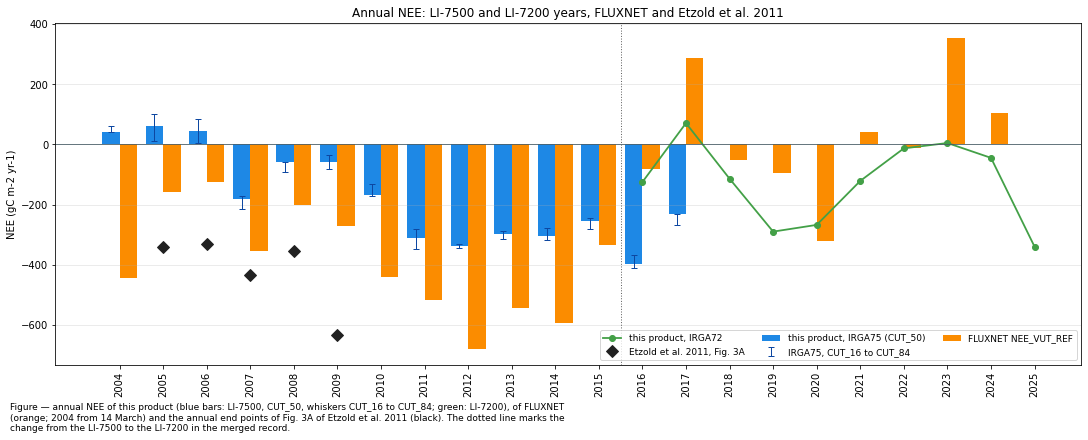

In [9]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
_x = annual.index.to_numpy()
_lo = annual[['IRGA75, CUT_16', 'IRGA75, CUT_84']].min(axis=1)
_hi = annual[['IRGA75, CUT_16', 'IRGA75, CUT_84']].max(axis=1)
_m = annual['IRGA75, CUT_50']
ax.bar(_x - 0.2, _m, width=0.4, color=COLORS['ours'], label="this product, IRGA75 (CUT_50)")
ax.errorbar(_x - 0.2, _m, yerr=[(_m - _lo).clip(lower=0), (_hi - _m).clip(lower=0)], fmt='none',
            ecolor='#0D47A1', capsize=3, lw=1, label="IRGA75, CUT_16 to CUT_84")
ax.bar(_x + 0.2, annual['FLUXNET'], width=0.4, color=COLORS['FLUXNET'], label="FLUXNET NEE_VUT_REF")
ax.plot(_x, annual['IRGA72, CUT_50'], color=COLORS['IRGA72'], marker='o', lw=1.8,
        label="this product, IRGA72")
ax.plot(list(ETZOLD_FIG3), list(ETZOLD_FIG3.values()), 'D', color=COLORS['study2011'], ms=8,
        label="Etzold et al. 2011, Fig. 3A")
ax.axhline(0, color='#455A64', lw=0.8)
ax.axvline(LI7500_ONLY[1] + 0.5, color='#616161', lw=1, ls=':')
year_axis(ax, _x)
ax.set_ylabel(f"NEE ({units_sum} yr-1)")
ax.set_title("Annual NEE: LI-7500 and LI-7200 years, FLUXNET and Etzold et al. 2011")
ax.grid(alpha=0.3, axis='y')
ax.legend(fontsize=9, ncol=3, loc='lower right')
figcap(fig, "annual NEE of this product (blue bars: LI-7500, CUT_50, whiskers CUT_16 to CUT_84; green: "
            "LI-7200), of FLUXNET (orange; 2004 from 14 March) and the annual end points of Fig. 3A of "
            "Etzold et al. 2011 (black). The dotted line marks the change from the LI-7500 to the LI-7200 in "
            "the merged record.")
fig.show()

## 📋 Table: the gap in numbers

In [10]:
def _mean(series, y0, y1):
    return series.loc[y0:y1].mean()


_ref72 = annual.loc[IRGA72_YEARS[0]:IRGA72_YEARS[1], 'IRGA72, CUT_50'].mean()
_rows = {}
for _lab, (_y0, _y1) in {**GROUPS, '2005-2009 (years of Etzold et al. 2011)': ETZOLD_YEARS}.items():
    _rows[_lab] = {
        'IRGA75, CUT_50': _mean(annual['IRGA75, CUT_50'], _y0, _y1),
        'IRGA75, CUT_16': _mean(annual['IRGA75, CUT_16'], _y0, _y1),
        'IRGA75, CUT_84': _mean(annual['IRGA75, CUT_84'], _y0, _y1),
        'FLUXNET': _mean(annual['FLUXNET'], max(_y0, 2005), _y1),
        'Etzold et al. 2011 (Fig. 3)': _mean(annual['Etzold et al. 2011 (Fig. 3)'], _y0, _y1),
        'IRGA72 mean 2016-2025': _ref72,
    }
gap = pd.DataFrame(_rows).T
gap['IRGA75 minus IRGA72'] = gap['IRGA75, CUT_50'] - gap['IRGA72 mean 2016-2025']
gap['IRGA75 minus FLUXNET'] = gap['IRGA75, CUT_50'] - gap['FLUXNET']
gap['IRGA75 minus Etzold et al. 2011'] = gap['IRGA75, CUT_50'] - gap['Etzold et al. 2011 (Fig. 3)']
gap.index.name = 'PERIOD'
display(styled(gap, caption=f"mean annual NEE in {units_sum} yr-1 per period. FLUXNET is averaged from 2005 "
                            f"(2004 is incomplete in FLUXNET). The last three columns are the gap of this "
                            f"product (CUT_50) to each reference; positive means less uptake in this product",
               subset=['IRGA75 minus IRGA72', 'IRGA75 minus FLUXNET', 'IRGA75 minus Etzold et al. 2011']))

Table — mean annual NEE in gC m-2 yr-1 per period. FLUXNET is averaged from 2005 (2004 is incomplete
in FLUXNET). The last three columns are the gap of this product (CUT_50) to each reference; positive
means less uptake in this product



,"IRGA75, CUT_50","IRGA75, CUT_16","IRGA75, CUT_84",FLUXNET,Etzold et al. 2011 (Fig. 3),IRGA72 mean 2016-2025,IRGA75 minus IRGA72,IRGA75 minus FLUXNET,IRGA75 minus Etzold et al. 2011
PERIOD,,,,,,,,,
2004-2006,48,21,82,-141,-335,-124,172,190,383
2007-2009,-98,-129,-91,-274,-474,-124,26,176,376
2010-2015,-279,-296,-259,-518,-,-124,-155,239,-
2005-2009 (years of Etzold et al. 2011),-38,-75,-18,-221,-418,-124,86,183,381


## 📋 Table: net uptake 2006-2009 against the biometric estimates

In [11]:
_y0, _y1 = ETZOLD_NEP_YEARS
_nep = {f"this product, -NEE, {k}": -annual.loc[_y0:_y1, f'IRGA75, {k}'].mean() for k in CUT_COLS}
_nep.update({f"Etzold et al. 2011, {k}": v for k, v in ETZOLD_NEP.items()})
_nep['FLUXNET, -NEE'] = -annual.loc[_y0:_y1, 'FLUXNET'].mean()
_nep['Etzold et al. 2011, -NEE (Fig. 3)'] = -annual.loc[_y0:_y1, 'Etzold et al. 2011 (Fig. 3)'].mean()
nep = pd.DataFrame({f'net uptake {_y0}-{_y1} ({units_sum} yr-1)': _nep})
nep['shortfall of this product (CUT_50)'] = nep.iloc[:, 0] - _nep['this product, -NEE, CUT_50']
nep.index.name = 'ESTIMATE'
display(styled(nep, caption=f"mean net uptake {_y0}-{_y1} (positive for a sink): -NEE of this product for "
                            f"the three USTAR scenarios, the four biometric estimates of the net ecosystem "
                            f"production of Etzold et al. 2011 (Table 5), FLUXNET and the eddy-covariance NEE of "
                            f"Etzold et al. 2011. The last column is each estimate minus this product",
               cmap=None))

Table — mean net uptake 2006-2009 (positive for a sink): -NEE of this product for the three USTAR
scenarios, the four biometric estimates of the net ecosystem production of Etzold et al. 2011 (Table
5), FLUXNET and the eddy-covariance NEE of Etzold et al. 2011. The last column is each estimate
minus this product



,net uptake 2006-2009 (gC m-2 yr-1),shortfall of this product (CUT_50)
ESTIMATE,,
"this product, -NEE, CUT_16",96,33
"this product, -NEE, CUT_50",63,0
"this product, -NEE, CUT_84",47,-16
"Etzold et al. 2011, NEP*",307,244
"Etzold et al. 2011, ΔC",429,366
"Etzold et al. 2011, NEP_BM",434,371
"Etzold et al. 2011, NEP_BEF",514,451
"FLUXNET, -NEE",237,174
"Etzold et al. 2011, -NEE (Fig. 3)",438,375


Against the LI-7200 years the gap lies in 2004-2006 (about +170 gC m⁻² per year) and is small in
2007-2009 (about +25); 2010-2015 take up more than the LI-7200 years. Against FLUXNET this product
is 175-240 gC m⁻² per year less negative in every period, against Etzold et al. (2011) about 380.
The biometric estimates of the net ecosystem production of 2006-2009 lie 240-450 gC m⁻² per year
above the net uptake of this product, beyond its USTAR range.

</br>

# Ruled out as causes

Each check asks whether a measurement or processing fault of the LI-7500 years could make their
uptake too small. None of them accounts for more than a small part of the gap.

## Analyser damping

The 18 EddyPro runs of 2004-2017 agree in 552 of 555 compared settings, the detected time lags lie
inside the window, the median AGC is 50 % in every summer, and the share of lags at a window limit
is 20.9 % in 2004-2007 against 16.1 % in 2008-2017. The correlation of `w` with H2O is 4.6-6.5 %
lower in 2004-2006 and not lower in 2007. Attributing all of it to the analyser, together with the
low CO2 gain, closes at most 34 % (2005), 45 % (2006) and 54 % (2007) of the summer daytime gap to
the LI-7200 years, or 67, 108 and 42 gC m⁻² of the May-September `NEE`. Evidence:
[`ANALYSER_DAMPING_CHECK_2004-2017`](../30_FLUX_POST-PROCESSING_CHAIN/IRGA75/ANALYSER_DAMPING_CHECK_2004-2017.ipynb).

## Covariance loss in the raw data

The 20 Hz data of June and July, 11-15 h, of 2005-2007, 2010-2012 and 2016 lose no covariance. At
the lag EddyPro used the covariance is 99.9-100 % of its extremum over -2 to +3 s; the cospectra
relative to `w`-`T_SONIC` match the reference years; white noise is below 1 % of the variance. All
measurement effects together change the covariance of `w` with CO2 by +0.9 % (2005) and +1.9 %
(2006). The correlation of CO2 with H2O is 8 % (2005) and 13 % (2006) lower than in 2010-2012,
more than that of `w` with either gas: the scalar exchange of these summers was less coupled, which
no analyser fault produces. Evidence:
[`RAW_DATA_DIAGNOSTICS_IRGA75_SUMMERS`](../30_FLUX_POST-PROCESSING_CHAIN/IRGA75/RAW_DATA_DIAGNOSTICS_IRGA75_SUMMERS.ipynb).

## CO2 gain and zero offset

Until the recalibration of December 2007 the LI-7500 read CO2 low. A low reading can be a gain error
(all densities and fluctuations scaled by the same factor g) or a zero offset (the mean density
shifted, the fluctuations unchanged). The two act on the flux in opposite directions:

- **Gain error.** The measured covariance, the WPL terms and the opco bias all scale with g, so the
  true corrected flux is `FC_L1.1_OPCO / g`: more uptake by day.
- **Zero offset.** The covariance is unchanged; the WPL terms and the opco bias, which scale with the
  mean CO2 density, are too small by the factor g. The true corrected flux is
  `FC_L1.1_OPCO + (1/g - 1) (WPL - BIAS_OPCO)`: less uptake by day.

The WPL terms are computed here from the columns of the input, `(ρc/ρd) E + (1 + ρv/ρd) ρc H / (ρ cp T)`
with molar densities. The field checks of 2007 point to a zero offset (table below). This
calculation was first made in a scratch analysis of 30 Oct 2026 whose script is not preserved; it
is recomputed here.

### 📋 Table: CO2 reading per year against the trend of 2008-2017

In [12]:
A = o75.join(n75[[NEE_QC, 'DAYTIME', 'NIGHTTIME']])
A['year'], A['month'] = A.index.year, A.index.month
_co2 = A[A['month'].isin(SUMMER) & (A.index.hour >= 11) & (A.index.hour <= 15)]
_co2y = _co2.groupby('year')['CO2_MIXING_RATIO'].median()
_fit = np.polyfit(_co2y.loc[GAIN_REF_YEARS[0]:GAIN_REF_YEARS[1]].index,
                  _co2y.loc[GAIN_REF_YEARS[0]:GAIN_REF_YEARS[1]].to_numpy(), 1)
CONC = pd.DataFrame({'CO2 median (umol mol-1)': _co2y, 'trend 2008-2017 (umol mol-1)': np.polyval(_fit, _co2y.index)})
CONC['CO2 gain g'] = CONC['CO2 median (umol mol-1)'] / CONC['trend 2008-2017 (umol mol-1)']
CONC['reading low (%)'] = (1 - CONC['CO2 gain g']) * 100
CONC.index.name = 'YEAR'
GAIN_CO2 = CONC['CO2 gain g'].where(CONC.index <= GAIN_EARLY[1], 1.0).clip(upper=1.0)
display(styled(CONC, caption=f"median CO2 mixing ratio of the LI-7500, May-September, 11 to 16 h, against the "
                             f"linear trend of {GAIN_REF_YEARS[0]}-{GAIN_REF_YEARS[1]} ({_fit[0]:.2f} umol mol-1 "
                             f"per year), and their ratio g. The scenarios below use g for "
                             f"{GAIN_EARLY[0]}-{GAIN_EARLY[1]} only",
               fmt={'CO2 median (umol mol-1)': "{:.1f}", 'trend 2008-2017 (umol mol-1)': "{:.1f}",
                    'CO2 gain g': "{:.3f}", 'reading low (%)': "{:.1f}"},
               subset=['reading low (%)'], cmap='Reds', center=False))

Table — median CO2 mixing ratio of the LI-7500, May-September, 11 to 16 h, against the linear trend
of 2008-2017 (2.11 umol mol-1 per year), and their ratio g. The scenarios below use g for 2004-2007
only



,CO2 median (umol mol-1),trend 2008-2017 (umol mol-1),CO2 gain g,reading low (%)
YEAR,,,,
2004,368.8,374.7,0.984,1.6
2005,369.6,376.8,0.981,1.9
2006,355.9,378.9,0.939,6.1
2007,358.1,381.1,0.940,6.0
2008,380.6,383.2,0.993,0.7
2009,386.1,385.3,1.002,-0.2
2010,392.8,387.4,1.014,-1.4
2011,388.8,389.5,0.998,0.2
2012,390.4,391.6,0.997,0.3


### 📋 Table: field checks of the CO2 calibration in 2007

In [13]:
# From the GIN fieldbook (legacy entries, redacted export), the only CO2 checks recorded before
# 2008; declared here because they are in no data file. Values in ppm.
CAL_CHECKS = pd.DataFrame([
    {'date': '2007-09-26', 'zero gas read': 31.02, 'reference gas': 449.5, 'reference read': 479.0,
     'note': 'internal chemicals changed shortly before; zero last set on 2006-02-07'},
    {'date': '2007-12-19', 'zero gas read': -46.6, 'reference gas': 567.5, 'reference read': 526.0,
     'note': 'check before the recalibration of the same day'},
]).set_index('date')
CAL_CHECKS['reference minus zero, read'] = CAL_CHECKS['reference read'] - CAL_CHECKS['zero gas read']
CAL_CHECKS['implied slope'] = CAL_CHECKS['reference minus zero, read'] / CAL_CHECKS['reference gas']
display(styled(CAL_CHECKS, caption="the field checks of the LI-7500 against zero gas and a reference gas "
                                   "recorded in 2007 (GIN fieldbook). On 19 December the zero read -46.6 ppm and "
                                   "the span between zero and reference is within 1 % of the true one: an offset, "
                                   "not a gain error. The check of September followed a change of chemicals and "
                                   "is less reliable",
               fmt={'zero gas read': "{:.1f}", 'reference gas': "{:.1f}", 'reference read': "{:.1f}",
                    'reference minus zero, read': "{:.1f}", 'implied slope': "{:.3f}"}, cmap=None))

Table — the field checks of the LI-7500 against zero gas and a reference gas recorded in 2007 (GIN
fieldbook). On 19 December the zero read -46.6 ppm and the span between zero and reference is within
1 % of the true one: an offset, not a gain error. The check of September followed a change of
chemicals and is less reliable



,zero gas read,reference gas,reference read,note,"reference minus zero, read",implied slope
date,,,,,,
2007-09-26,31.0,449.5,479.0,internal chemicals changed shortly before; zero last set on 2006-02-07,448.0,0.997
2007-12-19,-46.6,567.5,526.0,check before the recalibration of the same day,572.6,1.009


### 📋 Table: effect of a gain error or a zero offset on the summer daytime flux

In [14]:
_rho_d = A['DRYAIR_DENSITY'] / M_AIR  # dry air, mol m-3
_tk = A['TA_EP'] + (273.15 if A['TA_EP'].median() < 100 else 0.0)
_rho_cp = A['AIR_DENSITY'] * A['AIR_CP']  # J m-3 K-1
_c_ratio = A['CO2_MOLAR_DENSITY'] / 1000 / _rho_d  # mol mol-1
_v_ratio = A['H2O_MOLAR_DENSITY'] / 1000 / _rho_d
A['WPL'] = (_c_ratio * A['FH2O'] * 1000  # water vapour term, FH2O in mmol m-2 s-1
            + (1 + _v_ratio) * A['CO2_MOLAR_DENSITY'] * 1000 * A['H'] / (_rho_cp * _tk))  # thermal term
_g = A['year'].map(GAIN_CO2).fillna(1.0)
A['D_GAIN'] = (1 / _g - 1) * A['FC_L1.1_OPCO']
A['D_ZERO'] = (1 / _g - 1) * (A['WPL'] - A['BIAS_OPCO'])
_sd = A[A['month'].isin(SUMMER) & A['DAYTIME'].eq(1) & A[NEE_QC].notna() & A['WPL'].notna()]
_all_day = A[A['month'].isin(SUMMER) & A['DAYTIME'].eq(1)].groupby(['year', 'month']).size()
_mm = _sd.groupby(['year', 'month'])[['D_GAIN', 'D_ZERO']].mean()
_sums = (_mm.mul(_all_day.reindex(_mm.index), axis=0) * UMOL_TO_GC).groupby('year').sum()
CO2_EFFECT = pd.DataFrame({
    'g': GAIN_CO2,
    'corrected flux, mean (umol)': _sd.groupby('year')['FC_L1.1_OPCO'].mean(),
    'WPL terms, mean (umol)': _sd.groupby('year')['WPL'].mean(),
    'opco correction, mean (umol)': -_sd.groupby('year')['BIAS_OPCO'].mean(),
    'gain error: change (umol)': _sd.groupby('year')['D_GAIN'].mean(),
    'zero offset: change (umol)': _sd.groupby('year')['D_ZERO'].mean(),
    'gain error: May-Sep day (gC)': _sums['D_GAIN'],
    'zero offset: May-Sep day (gC)': _sums['D_ZERO'],
}).loc[GAIN_EARLY[0]:GAIN_EARLY[1]]
CO2_EFFECT.index.name = 'YEAR'
_chk = (_sd['FC'] - _sd['WPL']).median()
display(styled(CO2_EFFECT, caption=f"May-September daytime records that pass all tests, {GAIN_EARLY[0]}-"
                                   f"{GAIN_EARLY[1]}: the gain g, the mean corrected flux, the mean WPL terms and "
                                   f"the mean opco correction ({units}), and the change of the true corrected flux "
                                   f"if the low reading was a gain error or a zero offset; then the May-September "
                                   f"daytime sums of the change (monthly mean change times all daytime half-hours, "
                                   f"{units_sum}). Negative: more uptake. FC minus the WPL terms, the covariance part, "
                                   f"has a median of {_chk:.2f} {units} on these records",
               fmt={col: ("{:.3f}" if col == 'g' else "{:.2f}" if 'umol' in col else "{:.0f}")
                    for col in CO2_EFFECT.columns},
               subset=['gain error: change (umol)', 'zero offset: change (umol)',
                       'gain error: May-Sep day (gC)', 'zero offset: May-Sep day (gC)']))

Table — May-September daytime records that pass all tests, 2004-2007: the gain g, the mean corrected
flux, the mean WPL terms and the mean opco correction (µmol m-2 s-1), and the change of the true
corrected flux if the low reading was a gain error or a zero offset; then the May-September daytime
sums of the change (monthly mean change times all daytime half-hours, gC m-2). Negative: more
uptake. FC minus the WPL terms, the covariance part, has a median of -20.49 µmol m-2 s-1 on these
records



,g,"corrected flux, mean (umol)","WPL terms, mean (umol)","opco correction, mean (umol)",gain error: change (umol),zero offset: change (umol),gain error: May-Sep day (gC),zero offset: May-Sep day (gC)
YEAR,,,,,,,,
2004,0.984,-7.52,7.61,2.44,-0.12,0.16,-11,15
2005,0.981,-8.14,7.48,2.66,-0.16,0.20,-15,19
2006,0.939,-7.77,7.07,2.42,-0.50,0.61,-49,58
2007,0.940,-10.11,6.91,2.38,-0.65,0.60,-62,57


As a gain error the low reading would make the summer daytime flux of 2006-2007 more negative by
about the amount in the table, as a zero offset more positive by a similar amount. The field check
of December 2007 indicates an offset. Either way the effect is a few tens of gC m⁻² per summer in
2006-2007 and less in 2004-2005, against a gap to the LI-7200 years of several hundred; it does not
explain the weak uptake of 2005-2006.

## opco drivers across 2016

opco is fitted on 2016-2017 and applied to 2004-2015. If a driver changed its meaning at the start of
2016 (new sonic electronics, reinstallation of the boom on 8 January 2016, new radiation sensor), the
correction of the early years would be computed from a shifted input. Each driver is compared here
with the MeteoSwiss station Lägeren, which is independent of the tower, or with a relation internal
to the sonic, per year, matched by wind sector. The sonic record is taken from the LI-7500 input to
2015 and from the LI-7200 input from 2016; both carry the same sonic columns.

In [15]:
_son = pd.concat([o75.loc[:'2015-12-31 23:45', SONIC_COLS], i72.loc['2016-01-01':, SONIC_COLS]])
_son = _son[~_son.index.duplicated()]
J = _son.join(ms[['WS_LAE_MS', 'WD_LAE_MS', 'TA_LAE_MS', 'SW_IN_LAE_MS', 'FLAG_INCOMPLETE']], how='left')
J['year'] = J.index.year
J['day'] = J[SW47] > DAY_SW
J['jja'] = J.index.month.isin([6, 7, 8])
_ok_ms = J['FLAG_INCOMPLETE'].fillna(1) == 0
DRV = {}
# Sonic wind speed against the MeteoSwiss wind, matched by the MeteoSwiss wind sector.
_a = J[(J['WS_LAE_MS'] > 2) & J['WS'].between(0.3, 30) & (J['TAU_SSITC_TEST'] <= 1) & _ok_ms].copy()
_a['sec'] = sector(_a['WD_LAE_MS'])
_a['lr'] = np.log(_a['WS'] / _a['WS_LAE_MS'])
_w = _a['sec'].value_counts(normalize=True)
DRV['WS / WS_MS'] = np.exp(matched(_a, 'lr', ['sec'], _w))
DRV['WS / WS_MS, day'] = np.exp(matched(_a[_a['day']], 'lr', ['sec'], _w))
DRV['WS / WS_MS, night'] = np.exp(matched(_a[~_a['day']], 'lr', ['sec'], _w))
_an = _a[_a['ZL'].abs() < 0.1].copy()
_an['lu'] = np.log(_an['USTAR'] / _an['WS_LAE_MS'])
DRV['USTAR / WS_MS, neutral'] = np.exp(matched(_an, 'lu', ['sec'], _w))
# Relations internal to the sonic, near neutral, matched by the sonic wind sector.
_b = J[(J['WS'] > 2) & (J['TAU_SSITC_TEST'] <= 1) & (J['ZL'].abs() < 0.1) & (J['USTAR'] > 0.1)].copy()
_b['sec'] = sector(_b['WD'])
_wb = _b['sec'].value_counts(normalize=True)
_b['r'] = _b['USTAR'] / _b['WS']
_b['sw'] = _b['W_SIGMA'] / _b['USTAR']
DRV['USTAR / WS, neutral'] = matched(_b, 'r', ['sec'], _wb)
DRV['W_SIGMA / USTAR, neutral'] = matched(_b, 'sw', ['sec'], _wb)
_cc = J[(J['WS'] > 2) & (J['TAU_SSITC_TEST'] <= 1)].copy()
_cc['sec'] = sector(_cc['WD'])
DRV['pitch angle (deg)'] = matched(_cc, 'ROT_PITCH', ['sec'], _cc['sec'].value_counts(normalize=True))
# Sensible heat flux and temperatures.
_h = J[(J['H_SSITC_TEST'] <= 1) & J['H'].between(-200, 800)]
_hm = _h[_h['jja'] & (_h[SW47] > 600) & _h.index.hour.isin([11, 12, 13])]
DRV['H / SW_IN, JJA midday'] = (_hm['H'] / _hm[SW47]).groupby(_hm['year']).median()
_t = J[J['T_SONIC'].notna()].copy()
_t['dts'] = _t['T_SONIC'] - 273.15 * (_t['T_SONIC'] > 100) - _t[TA47]
DRV['T_SONIC - TA, night (K)'] = _t.loc[~_t['day'], 'dts'].groupby(_t.loc[~_t['day'], 'year']).median()
DRV['T_SONIC - TA, day (K)'] = _t.loc[_t['day'], 'dts'].groupby(_t.loc[_t['day'], 'year']).median()
_e = J[_ok_ms].copy()
_e['dta'] = _e[TA47] - _e['TA_LAE_MS']
DRV['TA - TA_MS, night (K)'] = _e.loc[~_e['day'], 'dta'].groupby(_e.loc[~_e['day'], 'year']).median()
DRV['TA - TA_MS, day (K)'] = _e.loc[_e['day'], 'dta'].groupby(_e.loc[_e['day'], 'year']).median()
_s = J[_ok_ms & (J['SW_IN_LAE_MS'] > 300) & (J[SW47] > 0)]
DRV['SW_IN / SW_IN_MS, above 300'] = (_s.groupby('year')[SW47].sum() / _s.groupby('year')['SW_IN_LAE_MS'].sum())
DRV = pd.DataFrame(DRV).loc[FIRST_YEAR:IRGA72_YEARS[1]]
DRV.index.name = 'YEAR'

### 📋 Table: drivers per year

In [16]:
display(styled(DRV, caption=f"per year, {FIRST_YEAR}-{IRGA72_YEARS[1]}: the sonic wind speed and USTAR against "
                            f"the MeteoSwiss wind (WS_MS above 2 m s-1, weighted over the MeteoSwiss wind sectors "
                            f"with fixed weights); USTAR / WS, W_SIGMA / USTAR (|z/L| below 0.1) and the pitch "
                            f"angle of the rotation, weighted over the sonic wind sectors; H relative to SW_IN at "
                            f"midday in June-August; the sonic temperature and the air temperature at 47 m against "
                            f"each other and against the MeteoSwiss station; and SW_IN against the station",
               fmt="{:.3f}", cmap=None))

Table — per year, 2004-2025: the sonic wind speed and USTAR against the MeteoSwiss wind (WS_MS above
2 m s-1, weighted over the MeteoSwiss wind sectors with fixed weights); USTAR / WS, W_SIGMA / USTAR
(|z/L| below 0.1) and the pitch angle of the rotation, weighted over the sonic wind sectors; H
relative to SW_IN at midday in June-August; the sonic temperature and the air temperature at 47 m
against each other and against the MeteoSwiss station; and SW_IN against the station



,WS / WS_MS,"WS / WS_MS, day","WS / WS_MS, night","USTAR / WS_MS, neutral","USTAR / WS, neutral","W_SIGMA / USTAR, neutral",pitch angle (deg),"H / SW_IN, JJA midday","T_SONIC - TA, night (K)","T_SONIC - TA, day (K)","TA - TA_MS, night (K)","TA - TA_MS, day (K)","SW_IN / SW_IN_MS, above 300"
YEAR,,,,,,,,,,,,,
2004,0.552,0.593,0.528,0.114,0.172,1.276,3.295,0.304,3.784,1.944,1.331,1.583,1.059
2005,0.511,0.543,0.489,0.106,0.170,1.267,3.755,0.281,4.657,2.536,1.131,1.439,1.044
2006,0.528,0.557,0.513,0.114,0.171,1.262,3.617,0.307,4.613,2.857,1.024,1.260,1.029
2007,0.545,0.568,0.528,0.113,0.172,1.256,4.281,0.279,4.840,2.511,1.097,1.315,1.043
2008,0.549,0.575,0.532,0.115,0.174,1.254,4.152,0.314,5.267,3.412,1.133,1.318,1.035
2009,0.526,0.543,0.512,0.113,0.172,1.269,3.671,0.298,4.958,2.584,1.102,1.406,1.034
2010,0.528,0.554,0.518,0.111,0.173,1.266,4.015,0.255,5.381,3.522,1.213,1.483,1.035
2011,0.510,0.525,0.497,0.106,0.171,1.268,3.629,0.327,4.760,2.605,1.243,1.586,0.975
2012,0.504,0.538,0.474,0.107,0.171,1.265,3.974,0.278,4.731,2.869,1.259,1.593,0.985


### 📋 Table: step of each driver at 2016

In [17]:
_rows = {}
for _k in DRV.columns:
    _s = DRV[_k]
    _pre, _post = _s.loc[DRIVER_PRE[0]:DRIVER_PRE[1]].mean(), _s.loc[DRIVER_POST[0]:DRIVER_POST[1]].mean()
    _sd = _s.loc[DRIVER_SD_YEARS[0]:DRIVER_SD_YEARS[1]].std()
    _rows[_k] = {f'{DRIVER_PRE[0]}-{DRIVER_PRE[1]}': _pre, f'{DRIVER_POST[0]}-{DRIVER_POST[1]}': _post,
                 'step': _post - _pre, 'step (%)': 100 * (_post / _pre - 1),
                 f'sd {DRIVER_SD_YEARS[0]}-{DRIVER_SD_YEARS[1]}': _sd, 'step / sd': (_post - _pre) / _sd,
                 '2004-2010': _s.loc[2004:2010].mean(), '2018-2025': _s.loc[2018:2025].mean()}
DRV_STEP = pd.DataFrame(_rows).T
DRV_STEP.index.name = 'DRIVER'
display(styled(DRV_STEP, caption=f"the step of each driver from {DRIVER_PRE[0]}-{DRIVER_PRE[1]} to the training "
                                 f"years {DRIVER_POST[0]}-{DRIVER_POST[1]}, in absolute terms, in % and relative to "
                                 f"the year-to-year standard deviation of {DRIVER_SD_YEARS[0]}-{DRIVER_SD_YEARS[1]}, "
                                 f"with the means of 2004-2010 and 2018-2025 for context",
               fmt="{:.3f}", subset=['step / sd'], cmap='RdBu_r', center=True))

Table — the step of each driver from 2013-2015 to the training years 2016-2017, in absolute terms,
in % and relative to the year-to-year standard deviation of 2006-2015, with the means of 2004-2010
and 2018-2025 for context



,2013-2015,2016-2017,step,step (%),sd 2006-2015,step / sd,2004-2010,2018-2025
DRIVER,,,,,,,,
WS / WS_MS,0.500,0.524,0.024,4.715,0.019,1.236,0.534,0.536
"WS / WS_MS, day",0.529,0.564,0.035,6.564,0.018,1.924,0.562,0.577
"WS / WS_MS, night",0.481,0.488,0.007,1.484,0.022,0.325,0.517,0.509
"USTAR / WS_MS, neutral",0.109,0.110,0.001,0.553,0.003,0.187,0.112,0.107
"USTAR / WS, neutral",0.178,0.170,-0.008,-4.636,0.003,-2.584,0.172,0.160
"W_SIGMA / USTAR, neutral",1.251,1.266,0.015,1.190,0.008,1.934,1.264,1.266
pitch angle (deg),3.647,4.507,0.860,23.582,0.255,3.376,3.827,4.745
"H / SW_IN, JJA midday",0.308,0.298,-0.010,-3.303,0.026,-0.385,0.291,0.323
"T_SONIC - TA, night (K)",4.834,5.209,0.375,7.766,0.322,1.168,4.786,4.740


### 📊 Plot: drivers per year

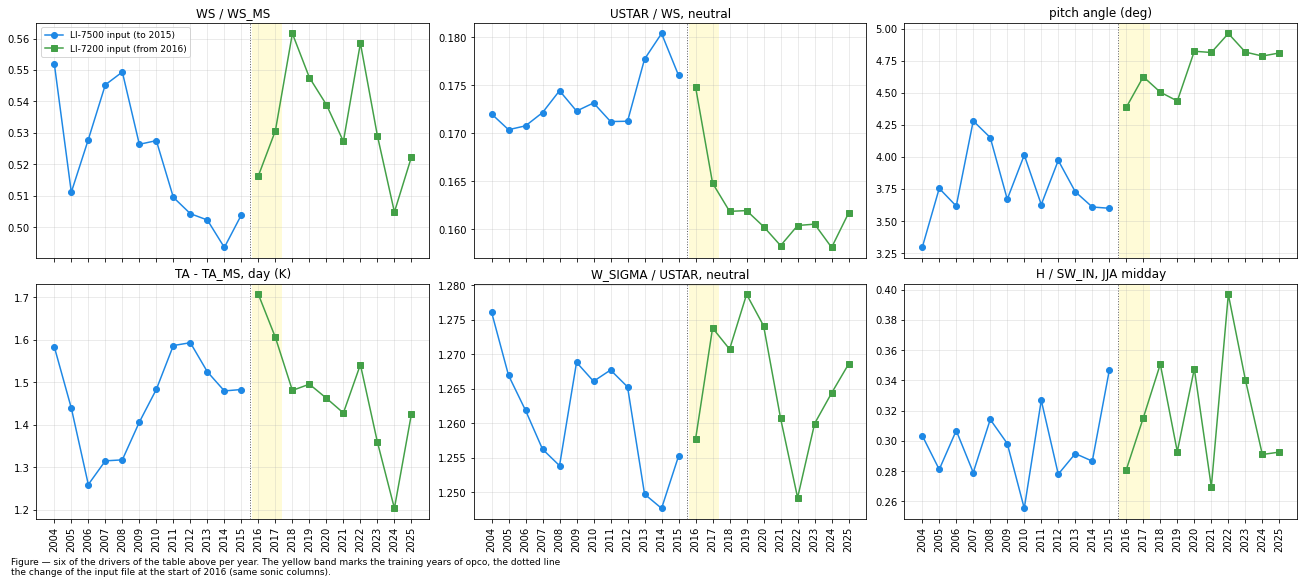

In [18]:
_show = ['WS / WS_MS', 'USTAR / WS, neutral', 'pitch angle (deg)', 'TA - TA_MS, day (K)',
         'W_SIGMA / USTAR, neutral', 'H / SW_IN, JJA midday']
fig, axs = plt.subplots(2, 3, figsize=(18, 8), dpi=72, layout="constrained", sharex=True)
for _ax, _k in zip(axs.flat, _show):
    _s = DRV[_k]
    _ax.plot(_s.loc[:LI7500_ONLY[1]].index, _s.loc[:LI7500_ONLY[1]], 'o-', color=COLORS['ours'],
             label="LI-7500 input (to 2015)")
    _ax.plot(_s.loc[PARALLEL_YEARS[0]:].index, _s.loc[PARALLEL_YEARS[0]:], 's-', color=COLORS['IRGA72'],
             label="LI-7200 input (from 2016)")
    _ax.axvline(LI7500_ONLY[1] + 0.5, color='#616161', lw=1, ls=':')
    _ax.axvspan(PARALLEL_YEARS[0] - 0.4, PARALLEL_YEARS[1] + 0.4, color='#FFF59D', alpha=0.4, lw=0)
    _ax.set_title(_k)
    _ax.grid(alpha=0.3)
for _ax in axs[-1]:
    year_axis(_ax, DRV.index)
axs[0, 0].legend(fontsize=9)
figcap(fig, "six of the drivers of the table above per year. The yellow band marks the training years of opco, "
            "the dotted line the change of the input file at the start of 2016 (same sonic columns).")
fig.show()

`WS` against the station is about 5 % lower in 2011-2015 than in 2016-2017, about 1.2 standard
deviations; 2004-2010 already lie at the level of 2016-2017. `USTAR / WS` lies at 0.170-0.174 in
2004-2012 and 0.176-0.180 in 2013-2015, and falls to 0.158-0.162 from 2018; the change does not
coincide with the start of 2016. The pitch angle rises by about 0.9° with the reinstallation of
January 2016; the coordinate rotation removes it. The temperatures and the radiation show no step
beyond the year-to-year spread.

### Sensitivity of opco to the drivers

opco is refitted here on 2016-2017 with the code and settings of `30_.../IRGA75/01` and then applied
to 2004-2015 with adjusted drivers: `WS` raised by the step of `WS / WS_MS` (in the heating term,
as a feature, or both), `WS` or `USTAR` scaled per year so that `USTAR / WS` takes the level of
the training years, and the daytime `TA` raised by the step of `TA - TA_MS`. The change of the
annual `NEE` is the mean change of the bias per year, day or night and half-year, times all
half-hours of that class.

In [19]:
from diive.flux.postprocessingchain import (init_flux_data, make_level32_detector, nighttime_uncertainty,
                                            run_level2, run_level31, run_level32)
from opco.physmodel import PhysBiasModel, drivers

_in75 = pd.read_parquet(DATADIR / FILE_IN75)
_in72 = pd.read_parquet(DATADIR / FILE_IN72).loc[TRAIN_START:TRAIN_END]
for _df in (_in75, _in72):
    _df.index = pd.DatetimeIndex(_df.index).as_unit('ns')
    _df.index.name = 'TIMESTAMP_MIDDLE'


def level32_accepted(dd, name):
    """True where FC of analyser `name` passes Levels 2 to 3.2 without a USTAR filter (as in IRGA75/01)."""
    dd = dd.drop(columns=[col for col in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if col in dd.columns])
    data = init_flux_data(df=dd, fluxcol='FC', site_lat=SITE_LAT, site_lon=SITE_LON, utc_offset=UTC_OFFSET,
                          nighttime_threshold=NIGHTTIME_THRESHOLD, daytime_accept_qcf_below=ACCEPT_QCF_BELOW,
                          nighttime_accept_qcf_below=ACCEPT_QCF_BELOW)
    data = run_level2(data, signal_strength=SIGNAL_STRENGTH[name], **LEVEL2_SETTINGS)
    data = run_level31(data, gapfill_storage_term=True, set_storage_to_zero=False, screen_storage_term=True,
                       concentration_col=CO2_CONC)
    data, sod = make_level32_detector(data)
    if REMOVE_DATES[name]:
        sod.flag_manualremoval_test(remove_dates=REMOVE_DATES[name], showplot=False, verbose=False)
        sod.addflag()
    sod.flag_outliers_abslim_test(minval=ABSLIM[0], maxval=ABSLIM[1], showplot=False, verbose=False)
    sod.addflag()
    sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                                  separate_day_night=True, showplot=False, verbose=False, repeat=True)
    sod.addflag()
    sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                                  by_time_of_day=True, time_of_day_slots=1, min_records=10,
                                  separate_day_night=True, showplot=False, verbose=False, repeat=True)
    sod.addflag()
    sigma = nighttime_uncertainty(data, sod, randunc_col=RANDUNC_COL, ta=OPCO_DRIVER_COLS['ta'],
                                  vpd=OPCO_DRIVER_COLS['vpd'], swin=OPCO_DRIVER_COLS['sw_in'])
    sod.flag_outliers_negative_night_test(uncertainty=sigma['POOLED'], z=NIGHT_Z, showplot=False, verbose=False)
    sod.addflag()
    data = run_level32(data, outlier_detector=sod)
    return data.levels.filteredseries_level32_qcf.notna().reindex(dd.index, fill_value=False)


_idx = _in72.index
_ok75 = level32_accepted(_in75.loc[TRAIN_START:TRAIN_END].copy(), 'IRGA75').reindex(_idx, fill_value=False)
_ok72 = level32_accepted(_in72.copy(), 'IRGA72').reindex(_idx, fill_value=False)
_keep = _ok75 & _ok72 & (_in72[FLOW_COL] >= FLOW_MIN)
_ref_fc = _in72['FC']
_df = _in75[list(dict.fromkeys(list(OPCO_DRIVER_COLS.values()) + [AGC_COL]))].copy()
del _in75, _in72


def opco_drivers(adjust=None):
    s = {k: _df[col].astype(float) for k, col in OPCO_DRIVER_COLS.items()}
    s['p'] = s['p'] * P_FACTOR
    if adjust is not None:
        s = adjust(s)
    ok = (_df[AGC_COL] <= AGC_MAX) | (_df.index > pd.Timestamp(AGC_SCREEN_END))
    return drivers(**s, ok=ok, origin=WEEK_ORIGIN)


D0 = opco_drivers()
_tr = D0.loc[TRAIN_START:TRAIN_END].copy()
_tr['dfc'] = _tr['fc'] - _ref_fc.reindex(_tr.index)
_train = _keep.reindex(_tr.index, fill_value=False) & _tr[['dfc', 'heat', 'wpl_h']].notna().all(axis=1)
OPCO_MODEL = PhysBiasModel(features_xi=FEATURES_XI, features_k=FEATURES_K, setup=SETUP).fit(_tr[_train])
BASE = OPCO_MODEL.predict(D0)
_rr = (BASE['bias'] - o75['BIAS_OPCO'].reindex(BASE.index)).loc[:IRGA75_LAST]
_rr_y = _rr.groupby(_rr.index.year).mean()
print(f"refit on {int(_train.sum()):,} training half-hours; mean IRGA75 - IRGA72 {_tr.loc[_train, 'dfc'].mean():.3f} "
      f"{units}")
print(f"refit minus stored BIAS_OPCO, mean per year 2004-2017: {_rr_y.min():+.3f} to {_rr_y.max():+.3f} {units} "
      f"(the tree fit is not bit-identical between runs)")

──────────────────────────────────── Initializing flux data: FC ────────────────────────────────────

> Detected base variable CO2 for FC. (CO2 was used to calculate FC.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

...

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

Random uncertainty of the 10,009 nighttime records
uncertainty   median at night   below -2 sigma   below -3 sigma
───────────────────────────────────────────────────────────────
FS                       0.81   1,001 (10.0 %)      680 (6.8 %)
PAS20                    3.63       77 (0.8 %)        7 (0.1 %)
MAX                      3.66       72 (0.7 %)        6 (0.1 %)
POOLED                   2.86      209 (2.1 %)       85 (0.8 %)
FS: EddyPro, sampling error of each half-hour. PAS20: spread of similar measurements (ONEFlux), a 
generous estimate. MAX: the larger of the two. POOLED: spread of all nighttime values within 15 days
on either side.

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT_TEST to flag data

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

refit on 13,792 training half-hours; mean IRGA75 - IRGA72 -1.850 µmol m-2 s-1
refit minus stored BIAS_OPCO, mean per year 2004-2017: -0.014 to +0.018 µmol m-2 s-1 (the tree fit is not bit-identical between runs)


#### 📋 Table: change of the annual NEE of 2004-2015 per driver variant

In [20]:
_early = _df.index < pd.Timestamp('2016-01-01')
_yr = pd.Series(_df.index.year, index=_df.index)
_ws_factor = DRV_STEP.loc['WS / WS_MS', f'{DRIVER_POST[0]}-{DRIVER_POST[1]}'] / DRV_STEP.loc[
    'WS / WS_MS', f'{DRIVER_PRE[0]}-{DRIVER_PRE[1]}']
_r = DRV['USTAR / WS, neutral']
_f_year = _r / _r.loc[DRIVER_POST[0]:DRIVER_POST[1]].mean()
_fy = _yr.map(_f_year).where(_early, 1.0).astype(float)
_ta_step = DRV_STEP.loc['TA - TA_MS, day (K)', 'step']


def _ws(s):
    s['u'] = s['u'].where(~_early, s['u'] * _ws_factor)
    return s


def _ws_year(s):
    s['u'] = s['u'] * _fy
    return s


def _ustar_year(s):
    s['ustar'] = s['ustar'] / _fy
    return s


def _ta_day(s):
    s['ta'] = s['ta'].where(~(_early & (s['sw_in'] > DAY_SW)), s['ta'] + _ta_step)
    return s


VARIANTS = {f'WS x {_ws_factor:.3f} (heating term and feature)': (_ws, None),
            f'WS x {_ws_factor:.3f}, heating term only': (_ws, 'heat_only'),
            f'WS x {_ws_factor:.3f}, feature only': (_ws, 'feature_only'),
            'WS scaled per year to the USTAR / WS of 2016-2017': (_ws_year, None),
            'USTAR scaled per year to the USTAR / WS of 2016-2017': (_ustar_year, None),
            f'daytime TA + {_ta_step:.2f} K': (_ta_day, None)}
_screen = (o75['FC_L1.1_OPCO'].notna() & (o75['FC_SSITC_TEST'] <= 1) & (o75['FC'].abs() <= 50)
           & (o75[AGC_COL] <= AGC_MAX)).reindex(_df.index, fill_value=False)
_isday = D0['isday'].astype(bool)
_half = pd.Series(np.where(_df.index.month.isin([10, 11, 12, 1, 2, 3]), 'Oct-Mar', 'Apr-Sep'), index=_df.index)
_nall = pd.DataFrame({'year': _yr, 'day': _isday, 'half': _half})[_early].groupby(['year', 'day', 'half']).size()
SENS = {}
for _lab, (_fun, _mode) in VARIANTS.items():
    _dd = opco_drivers(_fun)
    if _mode == 'heat_only':
        _dd['u'] = D0['u']
    elif _mode == 'feature_only':
        _dd['heat'] = D0['heat']
    _db = OPCO_MODEL.predict(_dd)['bias'] - BASE['bias']
    _sel = _screen & _early & _db.notna()
    _g = pd.DataFrame({'db': _db[_sel], 'year': _yr[_sel], 'day': _isday[_sel], 'half': _half[_sel]})
    _est = (_g.groupby(['year', 'day', 'half'])['db'].mean() * _nall).dropna() * UMOL_TO_GC
    SENS[_lab] = -_est.groupby(level='year').sum()  # NEE change: positive = less uptake
SENS = pd.DataFrame(SENS).loc[LI7500_ONLY[0]:LI7500_ONLY[1]]
SENS.index.name = 'YEAR'
_tab = SENS.copy()
_tab.loc['mean 2005-2015'] = SENS.loc[2005:2015].mean()
display(styled(_tab, caption=f"change of the annual NEE of {LI7500_ONLY[0]}-{LI7500_ONLY[1]} in {units_sum} if "
                             f"opco is applied with adjusted drivers (negative: more uptake). The factor on WS is "
                             f"the step of WS / WS_MS at 2016; the per-year factor is the USTAR / WS of each year "
                             f"relative to 2016-2017; the TA step is that of TA - TA_MS by day",
               fmt="{:.0f}"))

Table — change of the annual NEE of 2004-2015 in gC m-2 if opco is applied with adjusted drivers
(negative: more uptake). The factor on WS is the step of WS / WS_MS at 2016; the per-year factor is
the USTAR / WS of each year relative to 2016-2017; the TA step is that of TA - TA_MS by day



,WS x 1.047 (heating term and feature),"WS x 1.047, heating term only","WS x 1.047, feature only",WS scaled per year to the USTAR / WS of 2016-2017,USTAR scaled per year to the USTAR / WS of 2016-2017,daytime TA + 0.16 K
YEAR,,,,,,
2004,-25,-28,3,-8,-5,-5
2005,-27,-33,6,-2,-1,-5
2006,-24,-32,8,-3,-2,-3
2007,-23,-27,3,-7,-6,-4
2008,-29,-32,3,-16,-13,-5
2009,-28,-33,5,-9,-7,-4
2010,-29,-34,5,-13,-9,-5
2011,-25,-33,8,-5,-4,-4
2012,-27,-32,5,-5,-5,-4


Every variant moves the early years by less than 40 gC m⁻² per year, and all but one towards more
uptake. The largest, a wind speed raised by the step at 2016 in the heating term, gives -27 to
-37 gC m⁻² per year. Against the gap of about 170 gC m⁻² per year of 2004-2006 to the LI-7200
years this is at most a fifth, and against the gap of about 380 to Etzold et al. (2011) under a
tenth. The drivers do not explain the weak uptake.

## Clocks and timestamps

A shifted clock of the eddy-covariance system or of the meteo logger would move the diurnal course
of the fluxes against that of the radiation and could bias the light response and the gap-filling.
Per year, the centroid of the mean May-September diurnal course of each quantity is compared with
that of the potential radiation `SW_IN_POT`. The one known clock error, 6 to 12 July 2013 (7 hours),
is corrected in `30_.../IRGA75/00`.

### 📋 Table: centroid of the diurnal course against the potential radiation

In [21]:
def centroid_offset(frame, col, pot='SW_IN_POT', min_pot=20):
    """Per year: centroid time of the mean May-Sep diurnal course of `col` minus that of `pot`, minutes."""
    f = frame[frame.index.month.isin(SUMMER)]
    tod = f.index.hour * 60 + f.index.minute
    prof = f.groupby([f.index.year, tod])[[col, pot]].mean()
    out = {}
    for y, p in prof.groupby(level=0):
        p = p.droplevel(0)
        p = p[p[pot] > min_pot]
        x = p[col].clip(lower=0)
        if x.sum() <= 0 or len(p) < 20:
            continue
        cx = (x.index.to_numpy() * x).sum() / x.sum()
        cp_ = (p.index.to_numpy() * p[pot]).sum() / p[pot].sum()
        out[y] = cx - cp_
    return pd.Series(out)


_clk = o75[['SW_IN_POT', SW47, 'FLAG_SW_IN_T1_47_1_ISFILLED', 'H', 'H_SSITC_TEST', 'FC_L1.1_OPCO']].copy()
_clk['sw_meas'] = _clk[SW47].where(_clk['FLAG_SW_IN_T1_47_1_ISFILLED'] == 0)
_clk['h_ok'] = _clk['H'].where(_clk['H_SSITC_TEST'] <= 1)
_clk['uptake75'] = -n75[NEE_QC]
_clk['uptake72'] = -n72[NEE_QC].reindex(_clk.index)
_clk['ms_sw'] = ms['SW_IN_LAE_MS'].reindex(_clk.index)
_solar_noon = (_clk.groupby(_clk.index.hour * 60 + _clk.index.minute)['SW_IN_POT'].mean())
_noon = (_solar_noon.index.to_numpy() * _solar_noon).sum() / _solar_noon.sum()
_ms_off = centroid_offset(_clk, 'ms_sw')  # the station: independent clock, same weather
CLOCK = pd.DataFrame({
    'SW_IN, station, against SW_IN_POT': _ms_off,
    'SW_IN at 47 m': centroid_offset(_clk, 'sw_meas') - _ms_off,
    'H (sonic)': centroid_offset(_clk, 'h_ok') - _ms_off,
    '-NEE, IRGA75': centroid_offset(_clk, 'uptake75') - _ms_off,
    '-NEE, IRGA72': centroid_offset(_clk, 'uptake72') - _ms_off,
})
CLOCK.index.name = 'YEAR'
_tab = CLOCK.copy()
_tab.loc['median 2004-2015'] = CLOCK.loc[2004:2015].median()
_tab.loc['median 2016-2017'] = CLOCK.loc[2016:2017].median()
display(styled(_tab, caption=f"per year, May-September: the centroid of the mean diurnal course of SW_IN at the "
                             f"MeteoSwiss station minus that of the potential radiation (centroid of SW_IN_POT at "
                             f"{int(_noon // 60):02d}:{int(_noon % 60):02d} CET), and the centroid of each quantity "
                             f"of the tower minus that of the station, in minutes. Only times of day with a mean "
                             f"SW_IN_POT above 20 W m-2, negative values set to 0. SW_IN at 47 m is measured from "
                             f"September 2005. A clock error of one half-hour would move a tower column by about "
                             f"30 minutes", fmt="{:+.0f}", subset=['SW_IN at 47 m', 'H (sonic)', '-NEE, IRGA75',
                                                                   '-NEE, IRGA72'], cmap='RdBu_r', center=True))

Table — per year, May-September: the centroid of the mean diurnal course of SW_IN at the MeteoSwiss
station minus that of the potential radiation (centroid of SW_IN_POT at 12:14 CET), and the centroid
of each quantity of the tower minus that of the station, in minutes. Only times of day with a mean
SW_IN_POT above 20 W m-2, negative values set to 0. SW_IN at 47 m is measured from September 2005. A
clock error of one half-hour would move a tower column by about 30 minutes



,"SW_IN, station, against SW_IN_POT",SW_IN at 47 m,H (sonic),"-NEE, IRGA75","-NEE, IRGA72"
YEAR,,,,,
2004,+19,-,-2,-8,-
2005,+14,-12,-3,-7,-
2006,+16,-6,-1,+0,-
2007,+17,-5,-10,-10,-
2008,+16,-5,-8,-9,-
2009,+19,-16,-5,-7,-
2010,+16,-15,-13,+0,-
2011,+11,-17,-1,-12,-
2012,+13,-15,-2,+1,-


The station itself varies by several minutes from year to year against the potential radiation,
with the weather (2013: +32 minutes). Against the station, `H` and the uptake of the LI-7500 lie
within about ±15 minutes in every year, with no step between the early years and 2016-2017; the
radiation at 47 m lies 15-17 minutes before the station in 2009-2012 and within 12 minutes in the
other years. A clock error of a half-hour or more is excluded in every year.

</br>

# Size of the correction

opco adds 585-785 gC m⁻² per year to the uncorrected LI-7500 flux in 2005-2015 (table below). A
correction too large by a fraction of that would explain the weak uptake. This part collects the evidence on its size in the
early years.

## 📋 Table: the correction per year

In [22]:
_q = A[A[NEE_QC].notna()].copy()
_q['isday'] = _q['DAYTIME'].eq(1)
A['isday'] = A['DAYTIME'].eq(1)
_n = A.groupby(['year', 'month', 'isday']).size()
_m = _q.groupby(['year', 'month', 'isday'])[['BIAS_OPCO', 'BIAS_HEAT_OPCO']].mean()
_s = _m.mul(_n.reindex(_m.index), axis=0) * UMOL_TO_GC
_lv_m = _s.index.get_level_values('month')
_lv_d = np.asarray(_s.index.get_level_values('isday'), dtype=bool)
CORR_YEAR = pd.DataFrame({
    'opco, year': -_s['BIAS_OPCO'].groupby(level='year').sum(),
    'heating part, year': -_s['BIAS_HEAT_OPCO'].groupby(level='year').sum(),
    'opco, May-Sep day': -_s.loc[_lv_m.isin(SUMMER) & _lv_d, 'BIAS_OPCO'].groupby(level='year').sum(),
    'opco, Nov-Mar': -_s.loc[_lv_m.isin(WINTER_NIGHTS), 'BIAS_OPCO'].groupby(level='year').sum(),
    'opco, mean by day (umol)': -_q[_q['isday']].groupby('year')['BIAS_OPCO'].mean(),
    'opco, mean at night (umol)': -_q[~_q['isday']].groupby('year')['BIAS_OPCO'].mean(),
    'annual NEE (CUT_50)': per_year(n75[varname]),
})
CORR_YEAR.index.name = 'YEAR'
display(styled(CORR_YEAR, caption=f"the opco correction per year: the mean correction of the records that pass all "
                                  f"tests per month and day or night, times all half-hours of that class, in "
                                  f"{units_sum} (whole year, its heating part, May-September by day, November-March), "
                                  f"its mean by day and at night in {units}, and the annual NEE for comparison",
               fmt={col: ("{:.2f}" if 'umol' in col else "{:.0f}") for col in CORR_YEAR.columns}, cmap=None))

Table — the opco correction per year: the mean correction of the records that pass all tests per
month and day or night, times all half-hours of that class, in gC m-2 (whole year, its heating part,
May-September by day, November-March), its mean by day and at night in µmol m-2 s-1, and the annual
NEE for comparison



,"opco, year","heating part, year","opco, May-Sep day","opco, Nov-Mar","opco, mean by day (umol)","opco, mean at night (umol)",annual NEE (CUT_50)
YEAR,,,,,,,
2004,520,491,231,142,2.58,0.63,40
2005,761,791,254,355,3.07,0.83,62
2006,731,751,231,361,2.85,0.94,43
2007,588,614,226,207,2.57,0.57,-180
2008,685,740,265,268,2.84,0.77,-57
2009,784,783,259,360,3.11,0.92,-57
2010,780,798,266,329,3.17,0.96,-168
2011,721,724,253,302,3.05,0.90,-312
2012,670,720,253,276,2.90,0.77,-338


## Transfer of opco to the early years

opco transfers as a model: the drivers of the early summers lie inside the training range (at most
1.1 % of the records outside), the bias standardised to the same light and temperature is the same
in 2005-2009 and in 2016-2017 (ratio 1.03), and opco refitted on 2016 or on 2017 alone changes the
bias of 2005-2009 by at most 0.02 µmol m⁻² s⁻¹. Summer nights agree with the LI-7200 years. The
standardised summer daytime `NEE` lies +2.1 (2005), +2.7 (2006) and +0.9 to +1.2 µmol m⁻² s⁻¹
(2007-2009) above the LI-7200 years, +0.17 in 2010-2015; the gap is already in the uncorrected flux.
Evidence: [`OPCO_TRANSFER_CHECK_2004-2017`](../30_FLUX_POST-PROCESSING_CHAIN/IRGA75/OPCO_TRANSFER_CHECK_2004-2017.ipynb).

## Hardware of the LI-7500 years

A change of the analyser head, of its mounting or a factory recalibration would be the obvious
reason for a different self-heating. The records were searched for such events.

### 📋 Table: timeline of the LI-7500 and the sonic, 2003-2017

In [23]:
# Declared from the EC setup table (docs/Yearly_Notes.md) and the redacted GIN fieldbook export
# (fieldbook_gin/ in the data folder, legacy entries before June 2011); no data file holds them.
HARDWARE = pd.DataFrame([
    ('2003-10-24', 'fieldbook inventory', 'LI-7500 head 75H-0640 with analyser 75B0640 entered (backdated entry)'),
    ('2004-03-30', 'setup table', 'start of setup 2004_1: LI-7500 at 47 m, separation N+33 E0 V-5 cm from the sonic, '
                                  'sonic orientation 209°'),
    ('2005-09-30 to 2005-11-12', 'setup table', 'setups 2005_2 and 2005_3: a quantum cascade laser beside the LI-7500'),
    ('2006-02-07', 'fieldbook', 'zero of the LI-7500 set (last zero before September 2007)'),
    ('2007-09-26', 'fieldbook', 'internal chemicals changed, check and calibration'),
    ('2007-12-19', 'fieldbook', 'check (zero -46.6 ppm, 567.5 ppm read 526 ppm), then recalibration'),
    ('2008-05-16', 'fieldbook', 'calibration; setups 2008_2 and 2008_3 (to 2008-06-30) with a second analyser'),
    ('2010-12-16', 'fieldbook', 'reference measurement and calibration; head fastened with steel wire instead '
                                'of cable ties'),
    ('2011-05-10 to 2011-05-11', 'fieldbook', 'reference measurement, new internal chemicals, calibration'),
    ('2011-07-20', 'fieldbook', 'reference measurement at the hut, head demounted and remounted'),
    ('2011-09-01', 'fieldbook', 'power plug changed, head demounted and remounted'),
    ('2012-07-05', 'fieldbook', 'reference measurement on the tower'),
    ('2016-01-08', 'fieldbook', 'boom retracted, LI-7200 installed beside the LI-7500, radiation sensors replaced'),
    ('2016-01-14 to 2016-01-15', 'fieldbook', 'LI-7500 0640 referenced, chemicals replaced, calibrated in the lab, '
                                              'reinstalled'),
    ('2015-12-31', 'setup table', 'sonic entry changes from HS50-B to HS100 (the fieldbook has no sonic record '
                                  'before 2016)'),
    ('2017-12-12', 'setup table / fieldbook', 'end of setup 2017_1; LI-7500 removed'),
], columns=['date', 'source', 'event']).set_index('date')
display(styled(HARDWARE, caption="events of the LI-7500 and the sonic anemometer recorded in the EC setup table "
                                 "of the Yearly Notes and in the GIN fieldbook. One LI-7500 head (75H-0640) served "
                                 "from 2004 to 2017; no head exchange and no factory recalibration is recorded. "
                                 "Field calibrations were made in 2007, 2008, 2010, 2011 and 2016", cmap=None))

Table — events of the LI-7500 and the sonic anemometer recorded in the EC setup table of the Yearly
Notes and in the GIN fieldbook. One LI-7500 head (75H-0640) served from 2004 to 2017; no head
exchange and no factory recalibration is recorded. Field calibrations were made in 2007, 2008, 2010,
2011 and 2016



,source,event
date,,
2003-10-24,fieldbook inventory,LI-7500 head 75H-0640 with analyser 75B0640 entered (backdated entry)
2004-03-30,setup table,"start of setup 2004_1: LI-7500 at 47 m, separation N+33 E0 V-5 cm from the sonic, sonic orientation 209°"
2005-09-30 to 2005-11-12,setup table,setups 2005_2 and 2005_3: a quantum cascade laser beside the LI-7500
2006-02-07,fieldbook,zero of the LI-7500 set (last zero before September 2007)
2007-09-26,fieldbook,"internal chemicals changed, check and calibration"
2007-12-19,fieldbook,"check (zero -46.6 ppm, 567.5 ppm read 526 ppm), then recalibration"
2008-05-16,fieldbook,calibration; setups 2008_2 and 2008_3 (to 2008-06-30) with a second analyser
2010-12-16,fieldbook,reference measurement and calibration; head fastened with steel wire instead of cable ties
2011-05-10 to 2011-05-11,fieldbook,"reference measurement, new internal chemicals, calibration"


The same head was used throughout. The step of the wind test between 2007 and 2008 (below) falls
on the recalibration of December 2007, which changes the gain and the zero of the analyser but not
its heat output; no other change of the head or its mounting is recorded before 2010.

## Self-heating scale per year

Two tests from the LI-7500 data alone estimate a scale s of the self-heating, where s = 1 means the
size learned in 2016-2017. The method is that of section 4 of
[`OPCO_TRANSFER_CHECK_2004-2017`](../30_FLUX_POST-PROCESSING_CHAIN/IRGA75/OPCO_TRANSFER_CHECK_2004-2017.ipynb),
applied per year instead of to groups of years.

- **Wind test (summer).** The self-heating error is larger at low wind. Within cells of the same
  PPFD and air temperature, the difference of the flux between high wind (2.5-5 m s⁻¹) and low wind
  (below 1.5 m s⁻¹) is formed for the uncorrected flux and for the opco bias. With the contrast of the
  corrected flux of 2010-2017 as the ecosystem reference, s = (uncorrected contrast - reference) /
  bias contrast. The standard error uses the year-to-year spread of the LI-7200 contrast; a bootstrap
  over days gives the sampling error alone.
- **Winter test.** In November-February at -8 to 5 °C, sunny daytime records (SW_IN above
  150 W m⁻²) against nights, matched by temperature: the self-heating makes sunny days too negative.
  The corrected contrast of each winter against a reference contrast gives s = 1 + (corrected - reference)
  / bias contrast; the reference is either the eight training months or the middle winters
  2009/10-2014/15.

In [24]:
_c75 = ['FC', 'FC_L1.1_OPCO', 'BIAS_OPCO', 'BIAS_HEAT_OPCO', 'BIAS_WPL_H_OPCO', 'USTAR', 'WS', TA47, SW47]
SA = o75[_c75].join(n75[[NEE_QC, varname]]).join(met[['sw', 'sw_flag', 'ta', 'ppfd', 'ppfd_flag']])
SB = i72[['WS']].join(n72[[NEE_QC]]).join(met[['sw', 'sw_flag', 'ta', 'ppfd', 'ppfd_flag']])
SA['UNC'] = SA[NEE_QC] + SA['BIAS_OPCO']  # measured NEE without the correction
for _x in (SA, SB):
    _x['year'] = _x.index.year
    _x['summer'] = _x.index.month.isin(SUMMER)
    _x['ppfd_meas'] = _x['ppfd_flag'] == 0
Q75, Q72 = SA[NEE_QC].notna(), SB[NEE_QC].notna()
_rng = np.random.default_rng(0)


def _prep(dd, light='ppfd', light_bins=WIND_PPFD_BINS):
    s = dd.copy()
    s['cell'] = pd.cut(s[light], light_bins, labels=False) * 100 + pd.cut(s['ta'], TA_BINS, labels=False)
    s['wclass'] = np.select([s['WS'] <= WIND_LOW, (s['WS'] > WIND_HIGH[0]) & (s['WS'] <= WIND_HIGH[1])],
                            ['low', 'high'], 'mid')
    return s


def _contrast_one(g, cols):
    out = {}
    for col in cols:
        dev = g[col] - g.groupby('cell')[col].transform('mean')
        m = dev.groupby(g['wclass']).mean()
        out[col] = m.get('high', np.nan) - m.get('low', np.nan)
    return out


def wind_contrast(dd, cols):
    s = _prep(dd)
    rows = {}
    for y, g in s.groupby('year'):
        r = {'n low': int((g['wclass'] == 'low').sum()), 'n high': int((g['wclass'] == 'high').sum())}
        r.update(_contrast_one(g, cols))
        rows[y] = r
    return pd.DataFrame(rows).T


def boot_s(dd, ref):
    """Per year: bootstrap over days of (uncorrected contrast - ref) / bias contrast (sampling error only)."""
    s = _prep(dd)
    s['day'] = s.index.normalize()
    out = {}
    for y, g in s.groupby('year'):
        groups = [v for _, v in g.groupby('day')]
        vals = []
        for _ in range(N_BOOT):
            pick = _rng.integers(0, len(groups), size=len(groups))
            gb = pd.concat([groups[k] for k in pick])
            cc = _contrast_one(gb, ['UNC', 'BIAS_OPCO'])
            vals.append((cc['UNC'] - ref) / cc['BIAS_OPCO'])
        out[y] = np.nanstd(vals)
    return pd.Series(out)


_sel = lambda x: x['summer'] & x['ppfd_meas'] & (x['ppfd'] > WIND_PPFD_BINS[0])
_wa = SA[_sel(SA) & Q75 & (SA['year'] >= FIRST_LIGHT_YEAR)]
WIND75 = wind_contrast(_wa, ['UNC', 'BIAS_OPCO', NEE_QC]).rename(
    columns={'UNC': 'uncorrected', 'BIAS_OPCO': 'bias', NEE_QC: 'corrected'})
WIND72 = wind_contrast(SB[_sel(SB) & Q72], [NEE_QC]).rename(columns={NEE_QC: 'IRGA72'})
WIND_REF = WIND75.loc[WIND_REF_YEARS[0]:WIND_REF_YEARS[1], 'corrected'].mean()
SD_ECO = WIND72.loc[IRGA72_YEARS[0]:IRGA72_YEARS[1], 'IRGA72'].std()
NREF = WIND_REF_YEARS[1] - WIND_REF_YEARS[0] + 1
WIND = WIND75.copy()
WIND['s'] = (WIND['uncorrected'] - WIND_REF) / WIND['bias']
WIND['s SE'] = SD_ECO * np.sqrt(1 + 1 / NREF) / WIND['bias'].abs()
WIND['s SE, sampling only'] = boot_s(_wa, WIND_REF)
WIND.index.name = 'YEAR'
_rows = {}
for _grp, (_y0, _y1) in WIND_GROUPS.items():
    _w = WIND75.loc[_y0:_y1]
    _cb = _w['bias'].mean()
    _rows[_grp] = {'years': len(_w), 's': (_w['uncorrected'].mean() - WIND_REF) / _cb,
                   's SE': SD_ECO * np.sqrt(1 / len(_w) + 1 / NREF) / abs(_cb)}
WIND_GRP = pd.DataFrame(_rows).T
S_WIND_EARLY = float(WIND_GRP.loc['2005-2007', 's'])
print(f"wind test: reference contrast (corrected, {WIND_REF_YEARS[0]}-{WIND_REF_YEARS[1]}) {WIND_REF:+.2f} {units}; "
      f"year-to-year sd of the LI-7200 contrast {SD_ECO:.2f}")

wind test: reference contrast (corrected, 2010-2017) +0.06 µmol m-2 s-1; year-to-year sd of the LI-7200 contrast 1.09


### 📋 Table: wind test per year

In [25]:
_tab = WIND[['n low', 'n high', 'uncorrected', 'bias', 'corrected', 's', 's SE', 's SE, sampling only']].copy()
_tab = _tab.join(WIND72[['IRGA72']], how='outer').loc[FIRST_LIGHT_YEAR:IRGA72_YEARS[1]]
display(styled(_tab, caption=f"wind test per summer (May-September, measured PPFD above 200): number of low- and "
                             f"high-wind records, the wind contrast (high minus low, {units}) of the uncorrected "
                             f"LI-7500 flux, of the opco bias and of the corrected flux, the implied scale s with its "
                             f"standard error from the year-to-year spread of the LI-7200 and from a bootstrap over "
                             f"days, and the contrast of the LI-7200 in its own years",
               fmt={'n low': "{:.0f}", 'n high': "{:.0f}", 'uncorrected': "{:.2f}", 'bias': "{:.2f}",
                    'corrected': "{:.2f}", 's': "{:.2f}", 's SE': "{:.2f}", 's SE, sampling only': "{:.2f}",
                    'IRGA72': "{:.2f}"}, subset=['s'], cmap='RdBu', center=False))

Table — wind test per summer (May-September, measured PPFD above 200): number of low- and high-wind
records, the wind contrast (high minus low, µmol m-2 s-1) of the uncorrected LI-7500 flux, of the
opco bias and of the corrected flux, the implied scale s with its standard error from the year-to-
year spread of the LI-7200 and from a bootstrap over days, and the contrast of the LI-7200 in its
own years



,n low,n high,uncorrected,bias,corrected,s,s SE,"s SE, sampling only",IRGA72
2005,589,545,0.67,1.53,-0.86,0.40,0.75,0.43,-
2006,638,491,0.13,1.45,-1.33,0.05,0.80,0.43,-
2007,555,560,0.32,1.67,-1.36,0.15,0.69,0.40,-
2008,618,649,2.15,1.72,0.44,1.22,0.67,0.48,-
2009,666,526,1.78,1.67,0.12,1.03,0.69,0.45,-
2010,560,404,1.80,1.70,0.10,1.03,0.68,0.49,-
2011,527,565,0.93,1.78,-0.85,0.49,0.65,0.43,-
2012,495,573,2.52,1.66,0.86,1.48,0.70,0.55,-
2013,535,510,2.21,1.61,0.60,1.34,0.72,0.44,-
2014,659,516,1.96,1.70,0.26,1.12,0.68,0.45,-


### 📋 Table: wind test per group of years

In [26]:
display(styled(WIND_GRP, caption="the wind test over groups of years, as in OPCO_TRANSFER_CHECK_2004-2017: mean "
                                 "contrasts of the group, s and its standard error from the year-to-year spread of "
                                 "the LI-7200 and the number of reference years",
               fmt={'years': "{:.0f}", 's': "{:.2f}", 's SE': "{:.2f}"}, cmap=None))

Table — the wind test over groups of years, as in OPCO_TRANSFER_CHECK_2004-2017: mean contrasts of
the group, s and its standard error from the year-to-year spread of the LI-7200 and the number of
reference years



,years,s,s SE
2005-2007,3,0.20,0.48
2008-2009,2,1.13,0.51
2010-2015,6,1.06,0.35
2016-2017,2,0.84,0.47


In [27]:
_parts = [('IRGA75 uncorrected', SA.loc[Q75, 'UNC']), ('IRGA75 corrected', SA.loc[Q75, NEE_QC]),
          ('opco bias', SA.loc[Q75, 'BIAS_OPCO']), ('IRGA72', SB.loc[Q72, NEE_QC])]
L = pd.concat([pd.DataFrame({'series': _s, 'value': _v}) for _s, _v in _parts]).join(met[['sw', 'ta']])
L['month'] = L.index.month
LW = L[L['month'].isin(WINTER) & (L['ta'] >= WINTER_TA[0]) & (L['ta'] < WINTER_TA[1])].copy()
LW['cls'] = np.select([LW['sw'] <= 0, LW['sw'] >= SUNNY_SW], ['night', 'sunny'], 'other')
LW['tbin'] = pd.cut(LW['ta'], WINTER_TA_BINS)
LW['unit'] = LW.index.to_period('M')
_wsun = LW[(LW['series'] == 'IRGA75 uncorrected') & (LW['cls'] == 'sunny')]
W_WINTER = _wsun.groupby('tbin', observed=True).size() / len(_wsun)


def winter_contrast(g):
    sun, nig = g[g['cls'] == 'sunny'], g[g['cls'] == 'night']
    if len(sun) < WINTER_MIN_SUNNY or len(nig) < WINTER_MIN_NIGHT:
        return pd.Series({'contrast': np.nan, 'n_sunny': len(sun), 'n_night': len(nig)})
    ms_ = sun.groupby('tbin', observed=True)['value'].mean()
    mn_ = nig.groupby('tbin', observed=True)['value'].mean()
    ws_, wn_ = W_WINTER.reindex(ms_.index).fillna(0), W_WINTER.reindex(mn_.index).fillna(0)
    return pd.Series({'contrast': (ms_ * ws_).sum() / ws_.sum() - (mn_ * wn_).sum() / wn_.sum(),
                      'n_sunny': len(sun), 'n_night': len(nig)})


WC = LW.groupby(['series', 'unit']).apply(winter_contrast, include_groups=False).reset_index()
WC['start'] = WC['unit'].dt.start_time
WC = WC.dropna(subset=['contrast'])
_y = WC['start'].dt.year
WC['winter'] = np.where(WC['start'].dt.month >= 11, _y.astype(str) + '/' + (_y + 1).astype(str).str[2:],
                        (_y - 1).astype(str) + '/' + _y.astype(str).str[2:])
WC.loc[(WC['start'] >= TRAINING_WINTERS[0]) & (WC['start'] < TRAINING_WINTERS[1]), 'winter'] = 'training'
_cor = WC[WC['series'] == 'IRGA75 corrected'].set_index('unit')
_bia = WC[WC['series'] == 'opco bias'].set_index('unit')
_unc = WC[WC['series'] == 'IRGA75 uncorrected'].set_index('unit')
_trn = _cor.loc[_cor['winter'] == 'training', 'contrast']
_mid = _cor.loc[(_cor['start'] >= MIDDLE_WINTERS[0]) & (_cor['start'] < MIDDLE_WINTERS[1]), 'contrast']
_trn_se = _trn.std() / np.sqrt(len(_trn))


def _winter_s(units_):
    """s against the training months and against the middle winters for a set of months."""
    ce = _cor.loc[units_, 'contrast']
    be = _bia.loc[units_, 'contrast'].mean()
    s_tr = 1 + (ce.mean() - _trn.mean()) / be
    se_tr = np.sqrt((ce.std() / np.sqrt(len(ce))) ** 2 + _trn_se ** 2) / abs(be) if len(ce) > 1 else np.nan
    s_mid = 1 + (ce.mean() - _mid.mean()) / be
    se_mid = np.sqrt(_mid.std() ** 2 / len(ce) + _mid.std() ** 2 / len(_mid)) / abs(be)
    return {'months': len(ce), 'uncorrected contrast': _unc.loc[units_, 'contrast'].mean(),
            'bias contrast': be, 'corrected contrast': ce.mean(), 's vs training': s_tr, 'SE vs training': se_tr,
            's vs middle winters': s_mid, 'SE vs middle winters': se_mid}


_rows = {w: _winter_s(g.index) for w, g in _cor[_cor['winter'] != 'training'].groupby('winter')}
for _lab, (_a0, _b0) in WINTER_GROUPS.items():
    _rows[_lab] = _winter_s(_cor[(_cor['start'] >= _a0) & (_cor['start'] < _b0)].index)
WINTER_S = pd.DataFrame(_rows).T
WINTER_S.index.name = 'WINTER'
print(f"winter test: training months {len(_trn)}, corrected contrast {_trn.mean():+.2f} ± {_trn_se:.2f}; "
      f"middle winters {len(_mid)} months, {_mid.mean():+.2f} (sd {_mid.std():.2f})")

winter test: training months 8, corrected contrast +1.79 ± 2.42; middle winters 21 months, +1.02 (sd 3.57)


### 📋 Table: winter test per winter

In [28]:
display(styled(WINTER_S, caption=f"winter test per winter (November-February, {WINTER_TA[0]} to {WINTER_TA[1]} °C) "
                                 f"and for three groups of winters: months used, the mean monthly contrast sunny day "
                                 f"minus night ({units}) of the uncorrected flux, the opco bias and the corrected flux, "
                                 f"and s with its standard error against the eight training months and against the "
                                 f"middle winters 2009/10-2014/15",
               fmt={col: ("{:.0f}" if col == 'months' else "{:.2f}") for col in WINTER_S.columns},
               subset=['s vs training', 's vs middle winters'], cmap='RdBu', center=False))

Table — winter test per winter (November-February, -8 to 5 °C) and for three groups of winters:
months used, the mean monthly contrast sunny day minus night (µmol m-2 s-1) of the uncorrected flux,
the opco bias and the corrected flux, and s with its standard error against the eight training
months and against the middle winters 2009/10-2014/15



,months,uncorrected contrast,bias contrast,corrected contrast,s vs training,SE vs training,s vs middle winters,SE vs middle winters
WINTER,,,,,,,,
2004/05,4,-2.96,-4.47,1.51,1.06,0.67,0.89,0.44
2005/06,4,-4.29,-4.08,-0.21,1.49,0.64,1.30,0.48
2006/07,4,-5.79,-4.54,-1.25,1.67,0.73,1.50,0.43
2007/08,4,-4.28,-3.70,-0.58,1.64,0.84,1.43,0.53
2008/09,4,-1.87,-5.36,3.49,0.68,0.57,0.54,0.36
2009/10,3,-2.46,-4.22,1.76,1.01,0.61,0.82,0.52
2010/11,4,-0.85,-3.54,2.70,0.74,0.86,0.53,0.55
2011/12,4,-7.82,-5.41,-2.41,1.78,0.48,1.64,0.36
2012/13,3,-3.18,-5.05,1.87,0.98,0.69,0.83,0.44


### 📊 Plot: self-heating scale per year from the wind and winter tests

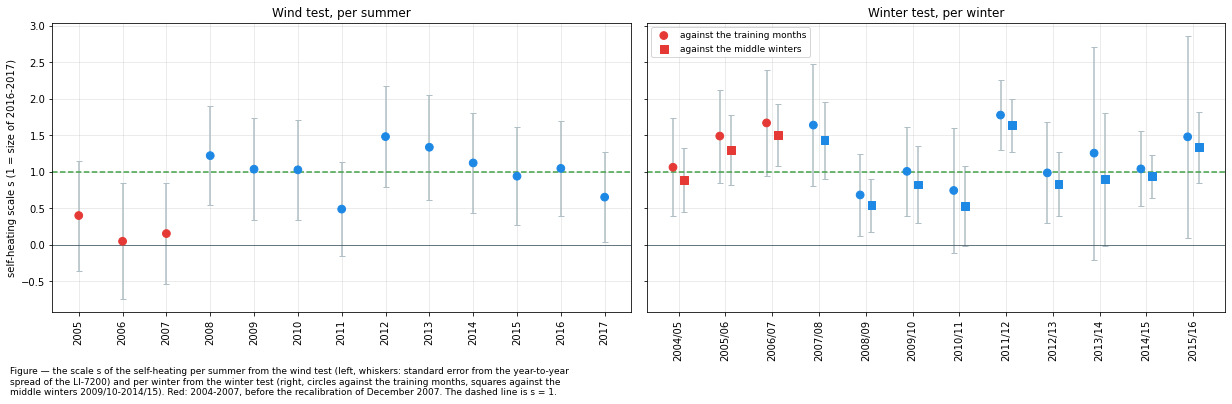

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(17, 5.5), dpi=72, layout="constrained", sharey=True)
_w = WIND.loc[FIRST_LIGHT_YEAR:PARALLEL_YEARS[1]]
_col = [COLORS['early'] if y <= 2007 else COLORS['ours'] for y in _w.index]
axs[0].errorbar(_w.index, _w['s'], yerr=_w['s SE'], fmt='none', ecolor='#B0BEC5', capsize=3)
axs[0].scatter(_w.index, _w['s'], c=_col, s=60, zorder=3)
year_axis(axs[0], _w.index)
axs[0].set_title("Wind test, per summer")
_ws_ = WINTER_S.drop(index=list(WINTER_GROUPS))
_x = np.arange(len(_ws_))
_col = [COLORS['early'] if w < '2007' else COLORS['ours'] for w in _ws_.index]
axs[1].errorbar(_x - 0.12, _ws_['s vs training'], yerr=_ws_['SE vs training'], fmt='none', ecolor='#B0BEC5', capsize=3)
axs[1].scatter(_x - 0.12, _ws_['s vs training'], c=_col, s=60, marker='o', zorder=3, label="against the training months")
axs[1].errorbar(_x + 0.12, _ws_['s vs middle winters'], yerr=_ws_['SE vs middle winters'], fmt='none',
                ecolor='#B0BEC5', capsize=3)
axs[1].scatter(_x + 0.12, _ws_['s vs middle winters'], c=_col, s=60, marker='s', zorder=3,
               label="against the middle winters")
axs[1].set_xticks(_x)
axs[1].set_xticklabels(_ws_.index, rotation=90)
axs[1].set_title("Winter test, per winter")
axs[1].legend(fontsize=9)
for _ax in axs:
    _ax.axhline(1, color=COLORS['IRGA72'], lw=1.5, ls='--')
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
axs[0].set_ylabel("self-heating scale s (1 = size of 2016-2017)")
figcap(fig, "the scale s of the self-heating per summer from the wind test (left, whiskers: standard error from the "
            "year-to-year spread of the LI-7200) and per winter from the winter test (right, circles against the "
            "training months, squares against the middle winters 2009/10-2014/15). Red: 2004-2007, before the "
            "recalibration of December 2007. The dashed line is s = 1.")
fig.show()

### 📋 Table: effect of a smaller scale on the May-September NEE of 2005-2007

In [30]:
_md = CORR_YEAR['opco, May-Sep day']
SCALE_EFFECT = pd.DataFrame({
    'opco, May-Sep day': _md,
    'wind test s (year, limited to 0-1)': WIND['s'].clip(0, 1),
}).loc[2005:2007]
SCALE_EFFECT[f'NEE change, s = {S_WIND_EARLY:.2f} (group)'] = -(1 - S_WIND_EARLY) * SCALE_EFFECT['opco, May-Sep day']
SCALE_EFFECT['NEE change, s of the year'] = -(1 - SCALE_EFFECT['wind test s (year, limited to 0-1)']) * SCALE_EFFECT['opco, May-Sep day']
SCALE_EFFECT['annual NEE (CUT_50)'] = CORR_YEAR['annual NEE (CUT_50)']
SCALE_EFFECT.index.name = 'YEAR'
display(styled(SCALE_EFFECT, caption=f"the May-September daytime opco correction ({units_sum}) of 2005-2007 and the "
                                     f"change of the May-September NEE if the self-heating were scaled by the wind-test "
                                     f"value of the group or of the year instead of 1 (negative: more uptake). Only the "
                                     f"daytime correction is scaled, as the wind test measures it",
               fmt={col: ("{:.2f}" if 's (' in col else "{:.0f}") for col in SCALE_EFFECT.columns}, cmap=None))

Table — the May-September daytime opco correction (gC m-2) of 2005-2007 and the change of the May-
September NEE if the self-heating were scaled by the wind-test value of the group or of the year
instead of 1 (negative: more uptake). Only the daytime correction is scaled, as the wind test
measures it



,"opco, May-Sep day","wind test s (year, limited to 0-1)","NEE change, s = 0.20 (group)","NEE change, s of the year",annual NEE (CUT_50)
YEAR,,,,,
2005,254,0.40,-203,-152,62
2006,231,0.05,-184,-220,43
2007,226,0.15,-181,-192,-180


The wind test gives about 0.2 for 2005-2007 and about 1 from 2008, with a step at the
recalibration of December 2007. The winter test of the same years gives s above 1 against either
reference and excludes 0.2. The wind test is the weaker of the two: within the training years it
gives 0.65 to 1.05, and its per-year scatter in 2008-2017 is about 0.3. s = 1 holds for 2008-2015.
For 2005-2007 a smaller scale is not shown, but neither is it excluded for summer alone; if it held,
the May-September `NEE` of these years would be up to about 200 gC m⁻² more negative. This is the
uncertainty stated for FP2026.2.

## Respiration constraint from the LI-7200 years

At night the open-path correction is about +0.5 to +1.0 µmol m⁻² s⁻¹. If it were too large, the
corrected nights of the LI-7500 years would lie above the respiration expected for their weather.
Five respiration models are fitted to the measured nights of the LI-7200 years 2016-2025: Lloyd-Taylor
of soil temperature at 0.1 m (one reference respiration, or one per calendar month), of soil
temperature at 0.05 m and of air temperature (one per month), and a boosted-tree model of soil and
air temperature, soil water and the season. They are applied to the LI-7500 nights; for the LI-7200
years each year is predicted by a model fitted without it. The ratio measured / expected is shown
for the corrected and the uncorrected flux on the same records.

In [31]:
R = met[['ta', 'ts10', 'ts10_method', 'ts05', 'ts05_method', 'swc10', 'swc10_source']].copy()
R = R.join(n75[['NIGHTTIME', NEE_QC, varname]].add_prefix('I75_')).join(
    n72[['NIGHTTIME', NEE_QC, varname]].add_prefix('I72_'))
R = R.join((-o75['BIAS_OPCO']).rename('OPCO_CORR'))
R = R.loc[:IRGA72_LAST]
R['YEAR'], R['MONTH'], R['DOY'] = R.index.year, R.index.month, R.index.dayofyear
R['TA'] = R['ta']
R['TS10'] = R['ts10'].where(R['ts10_method'].isin([1, 2]))  # measured soil temperature only
R['TS05'] = R['ts05'].where(R['ts05_method'].isin([1, 2]))
R['SWC_PCT'] = np.nan  # soil water as a percentile within each profile era (the profile changed in 2020)
for _e in (1, 2):
    _m = (R['swc10_source'] == _e) & R['swc10'].notna()
    R.loc[_m, 'SWC_PCT'] = R.loc[_m, 'swc10'].rank(pct=True)
R['DSIN'] = np.sin(2 * np.pi * R['DOY'] / 365.25)
R['DCOS'] = np.cos(2 * np.pi * R['DOY'] / 365.25)
_night = (R['I75_NIGHTTIME'] == 1) | (R['I72_NIGHTTIME'] == 1)
R['NIGHT'] = _night
R['M72'] = R[f'I72_{NEE_QC}'].where(_night)
R['M75C'] = R[f'I75_{NEE_QC}'].where(_night)
R['M75U'] = (R[f'I75_{NEE_QC}'] - R['OPCO_CORR']).where(_night)


def _lt(T, rref, e0):
    return rref * np.exp(e0 * (1.0 / (LT_TREF + 273.15 - LT_T0) - 1.0 / (T + 273.15 - LT_T0)))


class LTMonth:
    """Lloyd-Taylor with one E0 and a reference respiration per calendar month (or one in all)."""

    def __init__(self, tcol, per_month=True):
        self.tcol, self.per_month = tcol, per_month

    def fit(self, dd, y):
        T, idx = dd[self.tcol].to_numpy(), (dd['MONTH'].to_numpy() - 1) if self.per_month else np.zeros(len(dd), int)
        nr = 12 if self.per_month else 1
        res = least_squares(lambda p: _lt(T, p[:nr][idx], p[-1]) - y, np.r_[np.full(nr, 3.0), 200.0],
                            bounds=(np.r_[np.full(nr, 0.01), 20.0], np.r_[np.full(nr, 30.0), 800.0]))
        self.p, self.nr = res.x, nr
        return self

    def predict(self, dd):
        idx = (dd['MONTH'].to_numpy() - 1) if self.per_month else np.zeros(len(dd), int)
        return _lt(dd[self.tcol].to_numpy(), self.p[:self.nr][idx], self.p[-1])


class GBM:
    feats = ['TS10', 'TA', 'DSIN', 'DCOS', 'SWC_PCT']

    def fit(self, dd, y):
        self.m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                               min_samples_leaf=200, random_state=0).fit(dd[self.feats], y)
        return self

    def predict(self, dd):
        return self.m.predict(dd[self.feats])


RESP_MODELS = {'LT_TS10': (lambda: LTMonth('TS10', per_month=False), ['TS10']),
               'LT_TS10_MON': (lambda: LTMonth('TS10'), ['TS10']),
               'LT_TS05_MON': (lambda: LTMonth('TS05'), ['TS05']),
               'LT_TA_MON': (lambda: LTMonth('TA'), ['TA']),
               'GBM': (lambda: GBM(), ['TS10', 'TA', 'SWC_PCT'])}


def _classes(g):
    return {'all': np.ones(len(g), bool), 'TA<5': (g['TA'] < 5).to_numpy(),
            'TA>=12': (g['TA'] >= 12).to_numpy(), 'JJA': g['MONTH'].isin([6, 7, 8]).to_numpy()}


_rows = []
for _mname, (_mk, _need) in RESP_MODELS.items():
    _base = R[list(dict.fromkeys(_need + ['MONTH', 'YEAR', 'DSIN', 'DCOS', 'TA', 'TS10', 'SWC_PCT', 'M72', 'M75C', 'M75U']))].copy()
    _tr_all = _base.dropna(subset=_need + ['M72'])
    _tr_all = _tr_all[_tr_all['YEAR'].isin(RESP_YEARS72)]
    _ok = _base[_need].notna().all(axis=1)
    _pred = pd.Series(np.nan, index=_base.index)
    _pred[_ok] = _mk().fit(_tr_all, _tr_all['M72'].to_numpy()).predict(_base[_ok])
    for _y in RESP_YEARS72:  # leave one year out for the LI-7200 years
        _sel = _ok & (_base['YEAR'] == _y)
        if _sel.sum():
            _trn_y = _tr_all[_tr_all['YEAR'] != _y]
            _pred[_sel] = _mk().fit(_trn_y, _trn_y['M72'].to_numpy()).predict(_base[_sel])
    R[f'EXP_{_mname}'] = _pred
    _base['EXP'] = _pred
    for _tag, _col in {'IRGA72': 'M72', 'IRGA75 corrected': 'M75C', 'IRGA75 uncorrected': 'M75U'}.items():
        for _y, _g in _base.groupby('YEAR'):
            for _cl, _msk in _classes(_g).items():
                _v = _g.loc[_msk, [_col, 'EXP']].dropna()
                if len(_v) >= 30:
                    _rows.append({'model': _mname, 'series': _tag, 'YEAR': _y, 'cls': _cl, 'n': len(_v),
                                  'ratio': _v[_col].mean() / _v['EXP'].mean(), 'diff': (_v[_col] - _v['EXP']).mean()})
RESP = pd.DataFrame(_rows)
NIGHTS_PER_YEAR = R[_night].groupby('YEAR').size()
GC_PER_UMOL_NIGHTS = NIGHTS_PER_YEAR.loc[2005:2015].mean() * UMOL_TO_GC
print(f"{len(RESP_MODELS)} models fitted on {int(R['M72'].notna().sum()):,} measured LI-7200 nights; "
      f"1 {units} over all nights of a year = {GC_PER_UMOL_NIGHTS:.0f} {units_sum}")

5 models fitted on 32,262 measured LI-7200 nights; 1 µmol m-2 s-1 over all nights of a year = 190 gC m-2


### 📋 Table: measured over expected nighttime NEE per year

In [32]:
_mm = RESP.groupby(['series', 'YEAR', 'cls'])[['ratio', 'diff']].mean().reset_index()  # mean of the five models
RESP_RATIO = _mm.pivot_table(index='YEAR', columns=['cls', 'series'], values='ratio')
RESP_RATIO = RESP_RATIO.reindex(columns=pd.MultiIndex.from_product(
    [['all', 'TA<5', 'JJA'], ['IRGA75 corrected', 'IRGA75 uncorrected', 'IRGA72']]))
RESP_RATIO.columns = [f"{a}, {b}" for a, b in RESP_RATIO.columns]
display(styled(RESP_RATIO, caption="ratio of the mean measured nighttime NEE to the mean expected from the LI-7200 "
                                   "respiration models, mean of the five models, per year: all nights, nights below "
                                   "5 °C and June-August, for the corrected and the uncorrected LI-7500 flux on the "
                                   "same records and for the LI-7200 (each year predicted without it). 1 means as "
                                   "expected",
               fmt="{:.2f}", cmap='RdBu', center=False))

Table — ratio of the mean measured nighttime NEE to the mean expected from the LI-7200 respiration
models, mean of the five models, per year: all nights, nights below 5 °C and June-August, for the
corrected and the uncorrected LI-7500 flux on the same records and for the LI-7200 (each year
predicted without it). 1 means as expected



,"all, IRGA75 corrected","all, IRGA75 uncorrected","all, IRGA72","TA<5, IRGA75 corrected","TA<5, IRGA75 uncorrected","TA<5, IRGA72","JJA, IRGA75 corrected","JJA, IRGA75 uncorrected","JJA, IRGA72"
YEAR,,,,,,,,,
2004,0.79,0.62,-,0.69,0.45,-,0.87,0.77,-
2005,0.87,0.64,-,0.68,0.25,-,0.95,0.84,-
2006,1.00,0.73,-,0.87,0.27,-,1.14,1.02,-
2007,1.01,0.85,-,0.83,0.53,-,0.93,0.83,-
2008,1.08,0.87,-,1.13,0.68,-,0.91,0.80,-
2009,0.81,0.55,-,0.60,0.03,-,1.00,0.89,-
2010,0.94,0.68,-,0.71,0.14,-,0.93,0.83,-
2011,1.02,0.78,-,1.01,0.59,-,0.72,0.63,-
2012,0.89,0.68,-,0.93,0.54,-,0.97,0.87,-


### 📊 Plot: measured over expected nighttime NEE per year

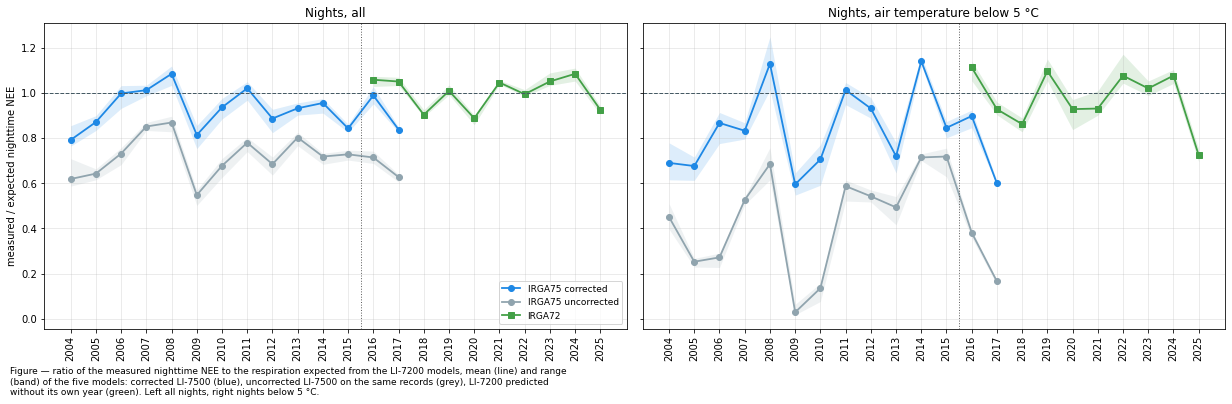

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(17, 5.5), dpi=72, layout="constrained", sharey=True)
for _ax, _cl in zip(axs, ('all', 'TA<5')):
    for _ser, _c, _mk in (('IRGA75 corrected', COLORS['ours'], 'o'), ('IRGA75 uncorrected', COLORS['noopco'], 'o'),
                          ('IRGA72', COLORS['IRGA72'], 's')):
        _sub = RESP[(RESP['series'] == _ser) & (RESP['cls'] == _cl)]
        _mean = _sub.groupby('YEAR')['ratio'].mean()
        _lo, _hi = _sub.groupby('YEAR')['ratio'].min(), _sub.groupby('YEAR')['ratio'].max()
        _ax.fill_between(_mean.index, _lo, _hi, color=_c, alpha=0.15, lw=0)
        _ax.plot(_mean.index, _mean, marker=_mk, color=_c, lw=1.8, label=_ser)
    _ax.axhline(1, color='#455A64', lw=1, ls='--')
    _ax.axvline(LI7500_ONLY[1] + 0.5, color='#616161', lw=1, ls=':')
    _ax.set_title(f"Nights, {'all' if _cl == 'all' else 'air temperature below 5 °C'}")
    _ax.grid(alpha=0.3)
    year_axis(_ax, range(FIRST_YEAR, IRGA72_YEARS[1] + 1))
axs[0].set_ylabel("measured / expected nighttime NEE")
axs[0].legend(fontsize=9, loc='lower right')
figcap(fig, "ratio of the measured nighttime NEE to the respiration expected from the LI-7200 models, mean (line) "
            "and range (band) of the five models: corrected LI-7500 (blue), uncorrected LI-7500 on the same records "
            "(grey), LI-7200 predicted without its own year (green). Left all nights, right nights below 5 °C.")
fig.show()

### 📋 Table: possible over-correction of the measured nights, in gC m⁻² per year

In [34]:
_b72 = _mm[_mm['series'] == 'IRGA72'].groupby('cls')['diff'].mean()
_b75 = _mm[(_mm['series'] == 'IRGA75 corrected') & _mm['YEAR'].isin(PARALLEL_YEARS)].groupby('cls')['diff'].mean()
_all = _mm[(_mm['cls'] == 'all') & (_mm['series'] == 'IRGA75 corrected')].set_index('YEAR')
_gf = {}
for _mname in ('LT_TS10_MON', 'LT_TA_MON', 'GBM'):
    _x = R.loc[_night, [f'I75_{varname}', f'EXP_{_mname}', 'YEAR']].dropna()
    _gf[_mname] = (_x[f'I75_{varname}'] - _x[f'EXP_{_mname}']).groupby(_x['YEAR']).mean() * NIGHTS_PER_YEAR * UMOL_TO_GC
_gf = pd.DataFrame(_gf).dropna(how='all')
RESP_GC = pd.DataFrame({
    'measured minus expected (umol)': _all['diff'],
    'excess over the IRGA72 level (gC)': (_all['diff'] - _b72['all']) * GC_PER_UMOL_NIGHTS,
    'excess over the IRGA75 level of 2016-2017 (gC)': (_all['diff'] - _b75['all']) * GC_PER_UMOL_NIGHTS,
    'all nights incl. gap-filled minus expected, min of 3 models (gC)': _gf.min(axis=1),
    'all nights incl. gap-filled minus expected, max of 3 models (gC)': _gf.max(axis=1),
}).loc[FIRST_YEAR:LAST_YEAR]
RESP_GC.index.name = 'YEAR'
display(styled(RESP_GC, caption=f"per year, the mean measured-minus-expected nighttime NEE of the corrected LI-7500 "
                                f"(mean of the five models, {units}); the same scaled to all nights of a year "
                                f"({GC_PER_UMOL_NIGHTS:.0f} {units_sum} per {units}) relative to the level of the LI-7200 "
                                f"years and to that of the corrected LI-7500 in 2016-2017, an upper bound of an "
                                f"over-correction if positive; and the gap-filled NEE of all nights minus the "
                                f"expected respiration, range of three models",
               fmt={col: ("{:.2f}" if 'umol' in col else "{:.0f}") for col in RESP_GC.columns}))

Table — per year, the mean measured-minus-expected nighttime NEE of the corrected LI-7500 (mean of
the five models, µmol m-2 s-1); the same scaled to all nights of a year (190 gC m-2 per µmol m-2
s-1) relative to the level of the LI-7200 years and to that of the corrected LI-7500 in 2016-2017,
an upper bound of an over-correction if positive; and the gap-filled NEE of all nights minus the
expected respiration, range of three models



,measured minus expected (umol),excess over the IRGA72 level (gC),excess over the IRGA75 level of 2016-2017 (gC),"all nights incl. gap-filled minus expected, min of 3 models (gC)","all nights incl. gap-filled minus expected, max of 3 models (gC)"
YEAR,,,,,
2004,-0.76,-143,-82,-212,-145
2005,-0.47,-90,-28,-144,-110
2006,-0.01,-2,59,-143,-85
2007,0.04,8,69,-106,-78
2008,0.30,57,118,-95,-49
2009,-0.69,-132,-71,-150,-110
2010,-0.24,-45,16,-208,-181
2011,0.07,14,75,-180,-105
2012,-0.44,-83,-22,-234,-179


The corrected LI-7500 nights lie at or below the expected respiration (ratio 0.79-1.08); the
uncorrected ones lie far below, most on nights below 5 °C (ratio 0.03-0.72). 2006-2008 are the
years in which the measured nights could be over-corrected, by at most 0.3 µmol m⁻² s⁻¹ (up to
57 gC m⁻² per year against the level of the LI-7200 years, up to 118 against that of the LI-7500
in 2016-2017). The night totals including the gap-filled nights lie below
expectation in every year, so the respiration constraint gives no room for a smaller correction at
night and does not reach the annual sums. Soil respiration from chambers (890 gC m⁻² per year in
2006-2009, Etzold et al. 2011) rules out the uncorrected flux but cannot size the correction; see
[`FLUX_NEE_IRGA75_INDEPENDENT_ESTIMATES`](FLUX_NEE_IRGA75_INDEPENDENT_ESTIMATES.ipynb).

## The correction of Etzold et al. (2011)

Etzold et al. (2011) corrected the same LI-7500 with the equation of Burba et al. (2008) and the
fraction 0.085 of Järvi et al. (2009), the surface temperature estimated from the sonic temperature.
The correction is recomputed here from the input of the chain, and the flux of this product is
shown with it in place of opco. Both corrections are removed or added on every half-hour as their
mean (opco) or median (Burba) per calendar month, by day and by night, since a gap-filled value
carries the correction of the measured values it is learned from. This is an approximation; the
full treatment is in [`FLUX_NEE_IRGA75_COMPARISONS`](FLUX_NEE_IRGA75_COMPARISONS.ipynb).

### 📋 Table: the two corrections, 2005-2009

In [35]:
E9 = d.loc[str(ETZOLD_YEARS[0]):str(ETZOLD_YEARS[1])].copy()
E9['opco_clim'] = month_night_climatology(E9, 'opco', 'mean')
E9['burba_clim'] = month_night_climatology(E9, 'burba', 'median')
E9['burba_clim_mean'] = month_night_climatology(E9, 'burba', 'mean')
_n9 = ETZOLD_YEARS[1] - ETZOLD_YEARS[0] + 1
CORR2 = pd.DataFrame({
    'opco': [E9.loc[~E9['night'], 'opco'].mean(), E9.loc[E9['night'], 'opco'].mean(), to_gc(E9['opco_clim']) / _n9],
    'Burba et al. 2008, median': [E9.loc[~E9['night'], 'burba'].median(), E9.loc[E9['night'], 'burba'].median(),
                                  to_gc(E9['burba_clim']) / _n9],
    'Burba et al. 2008, mean': [E9.loc[~E9['night'], 'burba'].mean(), E9.loc[E9['night'], 'burba'].mean(),
                                to_gc(E9['burba_clim_mean']) / _n9],
}, index=[f'by day ({units})', f'at night ({units})', f'added per year ({units_sum})']).T
CORR2.index.name = 'CORRECTION'
display(styled(CORR2, caption=f"the correction each method adds to the uncorrected LI-7500 flux, "
                              f"{ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}: per half-hour by day and at night (FLUXNET NIGHT), "
                              f"and per year as applied (monthly climatology on every half-hour)",
               fmt={f'by day ({units})': "{:.2f}", f'at night ({units})': "{:.2f}",
                    f'added per year ({units_sum})': "{:.0f}"}, cmap=None))

Table — the correction each method adds to the uncorrected LI-7500 flux, 2005-2009: per half-hour by
day and at night (FLUXNET NIGHT), and per year as applied (monthly climatology on every half-hour)



,by day (µmol m-2 s-1),at night (µmol m-2 s-1),added per year (gC m-2)
CORRECTION,,,
opco,2.56,0.69,638
"Burba et al. 2008, median",0.68,0.40,210
"Burba et al. 2008, mean",0.91,0.67,302


### 📋 Table: seasonal NEE with each correction, 2005-2009

In [36]:
E9['ours_noopco'] = E9['ours'] - E9['opco_clim']
E9['ours_burba'] = E9['ours_noopco'] + E9['burba_clim']
E9['ours_burba_mean'] = E9['ours_noopco'] + E9['burba_clim_mean']
_monthly = pd.DataFrame({
    'Etzold et al. 2011 (Fig. 5)': pd.Series(ETZOLD_FIG5, dtype=float),
    'this product, with opco': mean_monthly_sums(E9['ours']),
    'this product, without correction': mean_monthly_sums(E9['ours_noopco']),
    'this product, with Burba (median)': mean_monthly_sums(E9['ours_burba']),
    'this product, with Burba (mean)': mean_monthly_sums(E9['ours_burba_mean']),
    'FLUXNET': mean_monthly_sums(E9['flx']),
    f'IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}': mean_monthly_sums(r72[varname]),
}).sort_index()
SEAS = season_sums(_monthly)
SEAS.loc['Etzold et al. 2011 (published)'] = [np.nan] * len(SEASONS) + [ETZOLD_MEAN]
SEAS.index.name = 'SERIES'
display(styled(SEAS, caption=f"mean NEE per season and year in {units_sum}, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} "
                             f"unless stated: Etzold et al. 2011 from their Fig. 5 (±3 per month) and as published; "
                             f"this product with opco, without correction, and with the correction of Burba et al. "
                             f"2008 in place of opco (monthly median or mean); FLUXNET; the LI-7200 years"))

Table — mean NEE per season and year in gC m-2, 2005-2009 unless stated: Etzold et al. 2011 from
their Fig. 5 (±3 per month) and as published; this product with opco, without correction, and with
the correction of Burba et al. 2008 in place of opco (monthly median or mean); FLUXNET; the LI-7200
years



,Nov-Mar,Apr+Oct,May-Sep,year
SERIES,,,,
Etzold et al. 2011 (Fig. 5),156,0,-574,-418
"this product, with opco",310,61,-408,-38
"this product, without correction",7,-38,-645,-675
"this product, with Burba (median)",109,-8,-567,-466
"this product, with Burba (mean)",158,7,-538,-374
FLUXNET,183,19,-423,-221
IRGA72 2016-2025,370,36,-530,-124
Etzold et al. 2011 (published),-,-,-,-415


With the correction of Burba et al. (2008) in place of opco, this product reproduces the annual
sum and the seasonal pattern that Etzold et al. (2011) report. Most of the difference to their
study is therefore the size of the correction. The LI-7200 years decide only in part between the
two: in winter they agree with opco and not with the smaller correction, in summer they lie between
the two.

</br>

# Where the remaining difference sits

## Decomposition of the difference to FLUXNET

FLUXNET was built from the earlier product FP2021 (for 2004-2015 the LI-7500 flux with the
correction of Kittler et al. 2017) and filtered and gap-filled with ONEFlux. Each half-hour falls in
one of four classes: A both measured, B measured in this product only, C measured in FLUXNET only,
D both gap-filled. Each record is assigned to one cause, as in
[`FLUX_NEE_IRGA75_COMPARISONS`](FLUX_NEE_IRGA75_COMPARISONS.ipynb); a cause that acts through the
gap-filling also enters other classes, so the rows size the direct effect.

In [37]:
_bif = pd.read_csv(FLUXNET_DIR / FLUXNET_BIF, dtype=str)
_ref = (_bif[_bif['VARIABLE_GROUP'] == 'GRP_FLUX_REF']
        .pivot_table(index='GROUP_ID', columns='VARIABLE', values='DATAVALUE', aggfunc='first'))
del _bif
_ref = _ref[(_ref['REF_VARIABLE'] == 'NEE') & (_ref['REF_TIME_RESOLUTION'] == 'HH') & (_ref['REF_VERSION'] == 'VUT')]
USTAR_VUT = pd.Series(_ref['REF_USTAR_THRESHOLD'].astype(float).to_numpy(),
                      index=_ref['REF_YEAR'].astype(float).astype(int).to_numpy()).sort_index()
USTAR_CUT_50 = 0.304  # m s-1, the CUT_50 threshold of this product; docs/L3.3.md
fx = c.copy()
fx['ustar_vut'] = fx['year'].map(USTAR_VUT)
fx['reason'] = np.select(
    [(fx['cls'] == 'C') & fx['FC'].isna(), (fx['cls'] == 'C') & fx['ours_l32'].isna(),
     (fx['cls'] == 'C') & (fx['USTAR'] < USTAR_CUT_50), fx['cls'] == 'C',
     (fx['cls'] == 'B') & (fx['USTAR'] < fx['ustar_vut']), fx['cls'] == 'B'],
    ['C, no flux', 'C, quality and outlier tests', 'C, USTAR filter', 'C, other',
     'B, below the FLUXNET threshold', 'B, other'], '')
CAUSES = {
    'shared measured records (A): corrections': fx['cls'] == 'A',
    'negative nights FLUXNET keeps, removed by the tests here (C)': fx['reason'] == 'C, quality and outlier tests',
    'nights both gap-fill (D, night)': (fx['cls'] == 'D') & fx['night'],
    'USTAR filtering (B and C between the thresholds)': fx['reason'].isin(['C, USTAR filter',
                                                                         'B, below the FLUXNET threshold']),
    'days both gap-fill (D, day)': (fx['cls'] == 'D') & ~fx['night'],
    'other records measured in one product only (B, C)': fx['reason'].isin(['B, other', 'C, no flux', 'C, other']),
}
assert (pd.concat(CAUSES.values(), axis=1).sum(axis=1) == 1).all(), "the causes do not partition the records"

### 📋 Table: difference to FLUXNET per year and cause

In [38]:
FX_YEAR = pd.DataFrame({k: fx.loc[v].groupby('year')['diff'].sum() * UMOL_TO_GC for k, v in CAUSES.items()})
FX_YEAR = FX_YEAR.reindex(range(FIRST_YEAR, LAST_YEAR + 1)).fillna(0)
FX_YEAR['total, ours minus FLUXNET'] = FX_YEAR.sum(axis=1)
FX_YEAR['day'] = fx[~fx['night']].groupby('year')['diff'].sum() * UMOL_TO_GC
FX_YEAR['night'] = fx[fx['night']].groupby('year')['diff'].sum() * UMOL_TO_GC
assert np.allclose(FX_YEAR['total, ours minus FLUXNET'], FX_YEAR['day'] + FX_YEAR['night'])
FX_YEAR.loc['mean 2005-2015'] = FX_YEAR.loc[2005:2015].mean()
FX_YEAR.index.name = 'YEAR'
display(styled(FX_YEAR, caption=f"difference of the annual NEE, this product minus FLUXNET, in {units_sum}, split by "
                                f"cause, with the total and its split by day and night (FLUXNET NIGHT). 2004 starts on "
                                f"14 March; in 2016-2017 FLUXNET uses the LI-7200 and this product its LI-7500. The last "
                                f"row is the mean of 2005-2015",
               subset=pd.IndexSlice[:, list(CAUSES)]))

Table — difference of the annual NEE, this product minus FLUXNET, in gC m-2, split by cause, with
the total and its split by day and night (FLUXNET NIGHT). 2004 starts on 14 March; in 2016-2017
FLUXNET uses the LI-7200 and this product its LI-7500. The last row is the mean of 2005-2015



,shared measured records (A): corrections,"negative nights FLUXNET keeps, removed by the tests here (C)","nights both gap-fill (D, night)",USTAR filtering (B and C between the thresholds),"days both gap-fill (D, day)","other records measured in one product only (B, C)","total, ours minus FLUXNET",day,night
YEAR,,,,,,,,,
2004,-5,64,172,1,58,-4,286,68,218
2005,24,26,105,1,37,28,221,81,140
2006,21,36,129,2,-42,22,167,-24,191
2007,-4,37,98,0,38,3,172,20,152
2008,-5,39,76,1,13,20,144,-3,146
2009,27,38,153,3,-21,13,213,-8,221
2010,25,36,126,3,57,26,273,76,197
2011,21,43,85,3,35,18,204,63,141
2012,25,49,184,-0,72,12,342,106,236


In 2005-2015 the nights that both products gap-fill carry most of the difference, followed by the
negative winter nights that FLUXNET keeps and this product removes. The corrections on the shared
measured records, the USTAR filtering and the gap-filled days contribute little. The difference to
FLUXNET is therefore a matter of the night, mostly of the gap-filling, and not of the daytime
uptake.

## Gap-filled winter nights

FLUXNET fills its winter nights close to zero, from the low and negative measured nights it keeps.
This product fills its winter nights lower than it measures them. The table compares the measured
and the gap-filled nights of November to March per winter with the LI-7200 winters.

### 📋 Table: winter nights per winter, measured and gap-filled

In [39]:
def _winter_label(idx):
    y = idx.year - (idx.month <= 3)
    return pd.Index([f"{a}/{str(a + 1)[2:]}" for a in y])


_w75 = c[c['night'] & c['month'].isin(WINTER_NIGHTS)].copy()
_w75['winter'] = _winter_label(_w75.index)
_w72 = r72[r72['night'] & r72.index.month.isin(WINTER_NIGHTS)].copy()
_w72['winter'] = _winter_label(_w72.index)
WN = pd.DataFrame({
    'ours, measured': _w75[_w75['ours_meas']].groupby('winter')['ours'].mean(),
    'ours, filled': _w75[~_w75['ours_meas']].groupby('winter')['ours'].mean(),
    'ours, filled (%)': (~_w75['ours_meas']).groupby(_w75['winter']).mean() * 100,
    'FLUXNET, measured': _w75[_w75['flx_meas']].groupby('winter')['flx'].mean(),
    'FLUXNET, filled': _w75[~_w75['flx_meas']].groupby('winter')['flx'].mean(),
})
WN['ours, filled minus measured'] = WN['ours, filled'] - WN['ours, measured']
_wn72 = pd.DataFrame({
    'ours, measured': _w72[_w72['meas']].groupby('winter')[varname].mean(),
    'ours, filled': _w72[~_w72['meas']].groupby('winter')[varname].mean(),
    'ours, filled (%)': (~_w72['meas']).groupby(_w72['winter']).mean() * 100,
})
_wn72['ours, filled minus measured'] = _wn72['ours, filled'] - _wn72['ours, measured']
_wn72.index = [f"{w}, IRGA72" for w in _wn72.index]
_keep = [w for w in WN.index if '2003' not in w and w != '2017/18']
WINTER_NIGHTS_TAB = pd.concat([WN.loc[_keep], _wn72.drop(index=[w for w in _wn72.index if w.startswith('2015') or w.startswith('2025')])])
WINTER_NIGHTS_TAB.loc['mean 2004/05-2014/15, IRGA75'] = WN.loc[[w for w in _keep if w < '2015']].mean()
WINTER_NIGHTS_TAB.loc['mean 2016/17-2024/25, IRGA72'] = _wn72.drop(
    index=[w for w in _wn72.index if w.startswith('2015') or w.startswith('2025')]).mean()
WINTER_NIGHTS_TAB.index.name = 'WINTER'
_vals = [col for col in WINTER_NIGHTS_TAB.columns if '%' not in col]
display(styled(WINTER_NIGHTS_TAB, caption=f"mean nighttime NEE of November to March per winter in {units}: this product "
                                          f"(LI-7500 to 2016/17, rows marked IRGA72 the LI-7200) measured and gap-filled, "
                                          f"the filled share, and FLUXNET measured and filled. Night: FLUXNET NIGHT for the "
                                          f"LI-7500 winters, NIGHTTIME of this product for the LI-7200 winters. Incomplete "
                                          f"winters at the ends are left out",
               fmt={col: ("{:.0f}" if '%' in col else "{:.2f}") for col in WINTER_NIGHTS_TAB.columns},
               subset=_vals, cmap='Reds', center=False))

Table — mean nighttime NEE of November to March per winter in µmol m-2 s-1: this product (LI-7500 to
2016/17, rows marked IRGA72 the LI-7200) measured and gap-filled, the filled share, and FLUXNET
measured and filled. Night: FLUXNET NIGHT for the LI-7500 winters, NIGHTTIME of this product for the
LI-7200 winters. Incomplete winters at the ends are left out



,"ours, measured","ours, filled","ours, filled (%)","FLUXNET, measured","FLUXNET, filled","ours, filled minus measured"
WINTER,,,,,,
2004/05,2.21,1.93,75,-0.30,-0.53,-0.28
2005/06,2.54,1.78,73,1.27,0.35,-0.76
2006/07,2.58,2.19,69,1.40,1.23,-0.40
2007/08,2.98,2.28,66,1.34,0.80,-0.70
2008/09,2.20,1.58,74,1.07,0.65,-0.62
2009/10,1.89,1.74,75,-0.10,-0.69,-0.16
2010/11,2.24,1.59,70,1.08,0.69,-0.65
2011/12,3.46,2.22,71,1.75,0.91,-1.24
2012/13,2.43,1.53,78,0.85,0.32,-0.89


### 📊 Plot: winter nights per winter

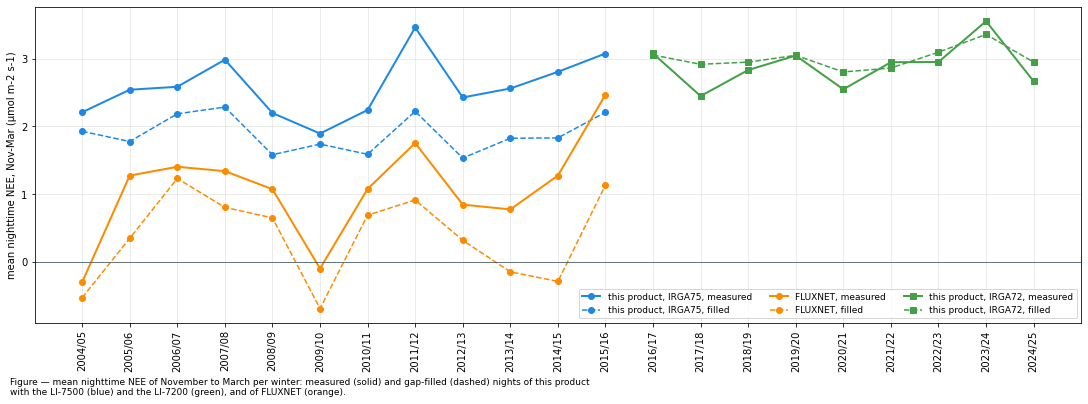

In [40]:
fig, ax = plt.subplots(figsize=(15, 5.5), dpi=72, layout="constrained")
_t75 = WN.loc[[w for w in _keep if w < '2016']]
_x75 = np.array([int(w[:4]) for w in _t75.index]) + 0.5
_t72 = _wn72.drop(index=[w for w in _wn72.index if w.startswith('2015') or w.startswith('2025')])
_x72 = np.array([int(w[:4]) for w in _t72.index]) + 0.5
ax.plot(_x75, _t75['ours, measured'], 'o-', color=COLORS['ours'], lw=2, label="this product, IRGA75, measured")
ax.plot(_x75, _t75['ours, filled'], 'o--', color=COLORS['ours'], lw=1.5, label="this product, IRGA75, filled")
ax.plot(_x75, _t75['FLUXNET, measured'], 'o-', color=COLORS['FLUXNET'], lw=2, label="FLUXNET, measured")
ax.plot(_x75, _t75['FLUXNET, filled'], 'o--', color=COLORS['FLUXNET'], lw=1.5, label="FLUXNET, filled")
ax.plot(_x72, _t72['ours, measured'], 's-', color=COLORS['IRGA72'], lw=2, label="this product, IRGA72, measured")
ax.plot(_x72, _t72['ours, filled'], 's--', color=COLORS['IRGA72'], lw=1.5, label="this product, IRGA72, filled")
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_xticks(np.r_[_x75, _x72])
ax.set_xticklabels(list(_t75.index) + [w.split(',')[0] for w in _t72.index], rotation=90)
ax.set_ylabel(f"mean nighttime NEE, Nov-Mar ({units})")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, ncol=3)
figcap(fig, "mean nighttime NEE of November to March per winter: measured (solid) and gap-filled (dashed) nights of "
            "this product with the LI-7500 (blue) and the LI-7200 (green), and of FLUXNET (orange).")
fig.show()

The gap-filled winter nights of the LI-7500 lie below its measured winter nights in most winters,
while those of the LI-7200 lie close to its measured nights. With most winter nights gap-filled,
this lowers the winter respiration of the LI-7500 years and so offsets part of their daytime deficit
in the annual sum. Whether the gap-filling of `IRGA75/05` fills the winter nights too low is open.

## Partitioning

The detailed comparison of `GPP` and `RECO` is in
[`FLUX_NEE_IRGA75_PARTITIONING_COMPARISON`](FLUX_NEE_IRGA75_PARTITIONING_COMPARISON.ipynb). In short:
the deficit of the early years lies in the daytime half-hours, the nighttime method assigns it to
`GPP`, and light-saturated `GPP` is lower without a later leaf-out. The daytime method splits `GPP`
and `RECO` unreliably across the analyser change. The table below gives the annual sums per group.

### 📋 Table: NEE by day and night, GPP and RECO per group of years

In [41]:
def _group_sums(frame, y0, y1):
    f = frame.loc[str(y0):str(y1)]
    n = y1 - y0 + 1
    return {'NEE': to_gc(f[varname]) / n, 'NEE, day': to_gc(f.loc[f['DAYTIME'] == 1, varname]) / n,
            'NEE, night': to_gc(f.loc[f['NIGHTTIME'] == 1, varname]) / n,
            'GPP (nighttime method)': to_gc(f['GPP_NT_OF_CUT_50']) / n,
            'RECO (nighttime method)': to_gc(f['RECO_NT_OF_CUT_50']) / n}


_rows = {f"{k}, IRGA75": _group_sums(n75, *v) for k, v in {'2005-2007': (2005, 2007), '2008-2009': (2008, 2009),
                                                           '2010-2015': (2010, 2015)}.items()}
_rows[f"{IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, IRGA72"] = _group_sums(n72, *IRGA72_YEARS)
PART = pd.DataFrame(_rows).T
_ref = PART.loc[f"{IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, IRGA72"]
for _col in ['NEE', 'NEE, day', 'NEE, night']:
    PART[f'{_col} minus IRGA72'] = PART[_col] - _ref[_col]
PART.index.name = 'GROUP'
display(styled(PART, caption=f"mean annual sums per group of years in {units_sum}: NEE, its daytime and nighttime "
                             f"part (DAYTIME and NIGHTTIME of this product), GPP and RECO of the nighttime partitioning "
                             f"(CUT_50), and the NEE parts minus the LI-7200 years",
               subset=[col for col in PART.columns if 'minus' in col]))

Table — mean annual sums per group of years in gC m-2: NEE, its daytime and nighttime part (DAYTIME
and NIGHTTIME of this product), GPP and RECO of the nighttime partitioning (CUT_50), and the NEE
parts minus the LI-7200 years



,NEE,"NEE, day","NEE, night",GPP (nighttime method),RECO (nighttime method),NEE minus IRGA72,"NEE, day minus IRGA72","NEE, night minus IRGA72"
GROUP,,,,,,,,
"2005-2007, IRGA75",-25,-602,577,1364,1339,99,220,-121
"2008-2009, IRGA75",-57,-644,587,1438,1381,67,178,-111
"2010-2015, IRGA75",-279,-831,552,1581,1302,-155,-9,-146
"2016-2025, IRGA72",-124,-822,698,1591,1467,0,0,0


Against the LI-7200 years the early LI-7500 years lose uptake by day and gain some at night. The
daytime deficit is the one the self-heating correction would have to explain; the nighttime gain
comes in part from the low gap-filled winter nights.

</br>

# Conclusion and open points

**Decided for FP2026.2**

- opco is used unchanged for 2004-2015. No check found a driver, a hardware change or a
  respiration bias that would justify another size of the correction in the early years.
- 2004-2009 are kept in the record without a confidence flag and without added uncertainty; the
  comparisons on the documentation page *Comparisons of the LI-7500 years* are their documentation.
- The May-September `NEE` of 2005-2007 is stated as uncertain by up to about 200 gC m⁻² towards
  more uptake, the size of the opco daytime correction that the summer wind test would remove.

**Open**

- **The QCL periods of 2005 and 2008.** A quantum cascade laser ran beside the LI-7500 from 30
  September to 12 November 2005 and from 16 May to 30 June 2008. If it measured CO2 at 20 Hz, its
  flux needs no self-heating correction and is a direct test of the size of opco in the early
  years themselves.
- **Winter night gap-filling of `IRGA75/05`.** The gap-filled winter nights of the LI-7500 lie
  below its measured winter nights; those of the LI-7200 do not.
- **2004.** Measurements start on 31 March 2004; whether 2004 gets an annual sum is not decided.
- **Later versions.** Improving the correction of the early years (a climate-expected baseline
  trained on the LI-7200 years, satellite greenness, dendrometer and inventory data) is deferred.

</br>

# End of notebook

In [42]:
_dt = datetime.now() - NOTEBOOK_START
print(f"Finished {datetime.now():%Y-%m-%d %H:%M:%S}; runtime {_dt.total_seconds() / 60:.1f} min")

Finished 2026-10-31 16:57:31; runtime 0.9 min
